In [1]:
# ============================================================
# CROSS-MODEL XAI — STEP 1
# CREATE COMMON TEST IMAGE SET
# ============================================================

import os
import json
import numpy as np
import pandas as pd

ROOT = r"D:\gpt\OcuVision-AI"

DATA_DIR = os.path.join(
    ROOT,
    "data",
    "preprocessed"
)

OUTPUT_DIR = os.path.join(
    ROOT,
    "results",
    "cross_model_xai"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

CLASSES = ["N", "D", "G", "C", "A", "H", "M"]

IMAGE_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp"
)

# ------------------------------------------------------------
# COLLECT IMAGES
# ------------------------------------------------------------

all_images = []

for class_name in CLASSES:

    class_dir = os.path.join(
        DATA_DIR,
        class_name
    )

    if not os.path.isdir(class_dir):
        print("WARNING: Missing:", class_dir)
        continue

    for filename in sorted(os.listdir(class_dir)):

        if filename.lower().endswith(IMAGE_EXTENSIONS):

            all_images.append({
                "path": os.path.join(
                    class_dir,
                    filename
                ),
                "filename": filename,
                "true_class": class_name
            })


print("Total images found:", len(all_images))


# ------------------------------------------------------------
# SELECT SAME 10 IMAGES
# ------------------------------------------------------------

rng = np.random.default_rng(42)

sample_size = min(10, len(all_images))

indices = rng.choice(
    len(all_images),
    size=sample_size,
    replace=False
)

selected = [
    all_images[i]
    for i in indices
]


# ------------------------------------------------------------
# SAVE COMMON IMAGE LIST
# ------------------------------------------------------------

rows = []

for i, item in enumerate(selected, start=1):

    rows.append({
        "sample_id": f"XAI_{i:02d}",
        "filename": item["filename"],
        "path": item["path"],
        "true_class": item["true_class"]
    })

common_df = pd.DataFrame(rows)

CSV_PATH = os.path.join(
    OUTPUT_DIR,
    "common_xai_test_images.csv"
)

common_df.to_csv(
    CSV_PATH,
    index=False
)


# ------------------------------------------------------------
# SAVE JSON TOO
# ------------------------------------------------------------

JSON_PATH = os.path.join(
    OUTPUT_DIR,
    "common_xai_test_images.json"
)

with open(JSON_PATH, "w") as f:
    json.dump(
        rows,
        f,
        indent=4
    )


# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("COMMON XAI TEST SET CREATED")
print("=" * 60)

print("\nNumber of images:", len(common_df))

print("\nSelected images:")
print(
    common_df[
        [
            "sample_id",
            "filename",
            "true_class"
        ]
    ].to_string(index=False)
)

print("\nSaved:")
print(CSV_PATH)

print(JSON_PATH)

Total images found: 10449

COMMON XAI TEST SET CREATED

Number of images: 10

Selected images:
sample_id              filename true_class
   XAI_01         2658_left.jpg          N
   XAI_02      _114_3613830.jpg          C
   XAI_03         2675_left.jpg          N
   XAI_04       Glaucoma156.jpg          G
   XAI_05          926_left.jpg          D
   XAI_06          791_left.jpg          D
   XAI_07       Glaucoma561.jpg          G
   XAI_08         2703_left.jpg          N
   XAI_09         3261_left.jpg          N
   XAI_10 0_ORID19_212_ARMD.png          A

Saved:
D:\gpt\OcuVision-AI\results\cross_model_xai\common_xai_test_images.csv
D:\gpt\OcuVision-AI\results\cross_model_xai\common_xai_test_images.json


In [7]:
# ============================================================
# CELL 2 — SIX-MODEL COMMON XAI PREDICTIONS
# CPU-SAFE VERSION
#
# IMPORTANT:
# This version intentionally uses CPU.
# It avoids CUDA OOM completely.
# ============================================================

from pathlib import Path
import gc

import torch
import torch.nn as nn
import pandas as pd

from PIL import Image
from torchvision import models, transforms
import timm


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(r"D:\gpt\OcuVision-AI")

COMMON_CSV = (
    ROOT /
    "results" /
    "cross_model_xai" /
    "common_xai_test_images.csv"
)

MODEL_DIR = ROOT / "models"

OUTPUT_DIR = (
    ROOT /
    "results" /
    "cross_model_xai"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. FORCE CPU
# ============================================================

device = torch.device("cpu")

print("=" * 70)
print("SIX-MODEL COMMON XAI PREDICTION")
print("=" * 70)

print("Device:", device)
print("CUDA intentionally disabled for this cell.")


# ============================================================
# 3. CLASSES
# ============================================================

classes = [
    "N",
    "D",
    "G",
    "C",
    "A",
    "H",
    "M"
]


# ============================================================
# 4. LOAD COMMON XAI CSV
# ============================================================

common_df = pd.read_csv(
    COMMON_CSV
)

print("\nCommon XAI images:")

print(
    common_df[
        [
            "sample_id",
            "filename",
            "true_class"
        ]
    ].to_string(index=False)
)


# ============================================================
# 5. TRANSFORMS
# ============================================================

transform_224 = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])


transform_299 = transforms.Compose([

    transforms.Resize(
        (299, 299)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])


# ============================================================
# 6. FIND IMAGE
# ============================================================

def find_image(filename):

    candidates = [

        ROOT / "data" / "preprocessed" / filename,

        ROOT / "data" / "preprocessed" / "train" / filename,

        ROOT / "data" / "preprocessed" / "test" / filename,

        ROOT / "data" / "preprocessed" / "val" / filename,

        ROOT / "data" / "preprocessed" / "validation" / filename,

        ROOT / "data" / "train" / filename,

        ROOT / "data" / "test" / filename,

        ROOT / "data" / "validation" / filename,

    ]

    for path in candidates:

        if path.is_file():
            return path


    matches = list(
        ROOT.rglob(filename)
    )

    if matches:
        return matches[0]


    raise FileNotFoundError(
        f"Could not find image: {filename}"
    )


# ============================================================
# 7. MODEL LOADERS
# ============================================================

def load_resnet():

    print("\nLoading ResNet-50...")

    model = models.resnet50(
        weights=None,
        num_classes=7
    )

    checkpoint = torch.load(
        MODEL_DIR / "resnet50_best_checkpoint.pth",
        map_location="cpu",
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model.eval()

    print("✓ ResNet-50 loaded")

    return model


def load_vit():

    print("\nLoading ViT-B/16...")

    model = models.vit_b_16(
        weights=None
    )

    model.heads.head = nn.Linear(
        model.heads.head.in_features,
        7
    )

    checkpoint = torch.load(
        MODEL_DIR / "vit_b16_best_checkpoint.pth",
        map_location="cpu",
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model.eval()

    print("✓ ViT-B/16 loaded")

    return model


def load_inception():

    print("\nLoading InceptionV3...")

    model = models.inception_v3(
        weights=None,
        aux_logits=True
    )

    model.fc = nn.Linear(
        model.fc.in_features,
        7
    )

    model.AuxLogits.fc = nn.Linear(
        model.AuxLogits.fc.in_features,
        7
    )

    checkpoint = torch.load(
        MODEL_DIR / "inception_v3_best_checkpoint.pth",
        map_location="cpu",
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model.eval()

    print("✓ InceptionV3 loaded")

    return model


def load_vgg16():

    print("\nLoading VGG16...")

    model = models.vgg16(
        weights=None
    )

    model.classifier[6] = nn.Linear(
        model.classifier[6].in_features,
        7
    )

    checkpoint = torch.load(
        MODEL_DIR / "vgg16_best_checkpoint.pth",
        map_location="cpu",
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model.eval()

    print("✓ VGG16 loaded")

    return model


def load_vgg19():

    print("\nLoading VGG19...")

    model = models.vgg19(
        weights=None
    )

    model.classifier[6] = nn.Linear(
        model.classifier[6].in_features,
        7
    )

    checkpoint = torch.load(
        MODEL_DIR / "vgg19_best_checkpoint.pth",
        map_location="cpu",
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model.eval()

    print("✓ VGG19 loaded")

    return model


def load_xception():

    print("\nLoading Xception...")

    model = timm.create_model(
        "legacy_xception",
        pretrained=False,
        num_classes=7
    )

    checkpoint = torch.load(
        MODEL_DIR / "xception_best_checkpoint.pth",
        map_location="cpu",
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model.eval()

    print("✓ Xception loaded")

    print(
        "Best epoch:",
        checkpoint["epoch"]
    )

    print(
        "Best Val Macro F1:",
        f"{checkpoint['best_val_macro_f1'] * 100:.2f}%"
    )

    return model


# ============================================================
# 8. PREDICTION FUNCTION
# ============================================================

@torch.no_grad()
def predict_model(
    model,
    image_path,
    transform
):

    image = Image.open(
        image_path
    ).convert("RGB")

    tensor = transform(
        image
    ).unsqueeze(0)

    output = model(
        tensor
    )

    if hasattr(
        output,
        "logits"
    ):
        output = output.logits

    elif isinstance(
        output,
        tuple
    ):
        output = output[0]

    probabilities = torch.softmax(
        output,
        dim=1
    )

    confidence, prediction = torch.max(
        probabilities,
        dim=1
    )

    predicted_class = classes[
        prediction.item()
    ]

    return (
        predicted_class,
        confidence.item()
    )


# ============================================================
# 9. RUN ONE MODEL
# ============================================================

def run_model(
    model_name,
    loader,
    transform
):

    print("\n")
    print("=" * 70)
    print(
        "RUNNING:",
        model_name
    )
    print("=" * 70)

    model = loader()

    records = []

    for i, row in common_df.iterrows():

        image_path = find_image(
            row["filename"]
        )

        prediction, confidence = (
            predict_model(
                model,
                image_path,
                transform
            )
        )

        records.append({

            "sample_id":
                row["sample_id"],

            "filename":
                row["filename"],

            "image_path":
                str(image_path),

            "true_class":
                row["true_class"],

            f"{model_name}_prediction":
                prediction,

            f"{model_name}_confidence":
                confidence
        })

        print(
            f"{i + 1:02d}/"
            f"{len(common_df)} | "
            f"True: {row['true_class']} | "
            f"Pred: {prediction} | "
            f"Confidence: "
            f"{confidence * 100:.2f}%"
        )

    del model

    gc.collect()

    print(
        f"\n✓ {model_name} complete"
    )

    return pd.DataFrame(
        records
    )


# ============================================================
# 10. RUN ALL SIX MODELS
# ============================================================

resnet_df = run_model(
    "resnet50",
    load_resnet,
    transform_224
)

vit_df = run_model(
    "vit_b16",
    load_vit,
    transform_224
)

inception_df = run_model(
    "inception_v3",
    load_inception,
    transform_299
)

vgg16_df = run_model(
    "vgg16",
    load_vgg16,
    transform_224
)

vgg19_df = run_model(
    "vgg19",
    load_vgg19,
    transform_224
)

xception_df = run_model(
    "xception",
    load_xception,
    transform_299
)


# ============================================================
# 11. MERGE RESULTS
# ============================================================

final_df = resnet_df.copy()


for df in [
    vit_df,
    inception_df,
    vgg16_df,
    vgg19_df,
    xception_df
]:

    prediction_columns = [
        col
        for col in df.columns
        if (
            "prediction" in col
            or "confidence" in col
        )
    ]

    final_df = final_df.merge(
        df[
            [
                "sample_id",
                "filename"
            ] + prediction_columns
        ],
        on=[
            "sample_id",
            "filename"
        ],
        how="left"
    )


# ============================================================
# 12. SAVE
# ============================================================

output_path = (
    OUTPUT_DIR /
    "six_model_xai_predictions.csv"
)

final_df.to_csv(
    output_path,
    index=False
)


# ============================================================
# 13. FINAL OUTPUT
# ============================================================

print("\n")
print("=" * 70)
print("SIX-MODEL XAI PREDICTIONS COMPLETE")
print("=" * 70)

print(
    final_df.to_string(
        index=False
    )
)

print("\nSaved to:")

print(
    output_path
)

print("=" * 70)

SIX-MODEL COMMON XAI PREDICTION
Device: cpu
CUDA intentionally disabled for this cell.

Common XAI images:
sample_id              filename true_class
   XAI_01         2658_left.jpg          N
   XAI_02      _114_3613830.jpg          C
   XAI_03         2675_left.jpg          N
   XAI_04       Glaucoma156.jpg          G
   XAI_05          926_left.jpg          D
   XAI_06          791_left.jpg          D
   XAI_07       Glaucoma561.jpg          G
   XAI_08         2703_left.jpg          N
   XAI_09         3261_left.jpg          N
   XAI_10 0_ORID19_212_ARMD.png          A


RUNNING: resnet50

Loading ResNet-50...
✓ ResNet-50 loaded
01/10 | True: N | Pred: N | Confidence: 93.53%
02/10 | True: C | Pred: C | Confidence: 99.93%
03/10 | True: N | Pred: N | Confidence: 99.47%
04/10 | True: G | Pred: G | Confidence: 99.52%
05/10 | True: D | Pred: D | Confidence: 99.97%
06/10 | True: D | Pred: D | Confidence: 99.84%
07/10 | True: G | Pred: G | Confidence: 99.67%
08/10 | True: N | Pred: N | Co

d:\gpt\OcuVision-AI\.venv\Lib\site-packages\torchvision\models\inception.py:43: FutureWarning: The default weight initialization of inception_v3 will be changed in future releases of torchvision. If you wish to keep the old behavior (which leads to long initialization times due to scipy/scipy#11299), please set init_weights=True.
  warnings.warn(


✓ InceptionV3 loaded
01/10 | True: N | Pred: N | Confidence: 48.44%
02/10 | True: C | Pred: C | Confidence: 99.34%
03/10 | True: N | Pred: D | Confidence: 68.47%
04/10 | True: G | Pred: D | Confidence: 36.24%
05/10 | True: D | Pred: D | Confidence: 95.30%
06/10 | True: D | Pred: D | Confidence: 76.88%
07/10 | True: G | Pred: G | Confidence: 74.68%
08/10 | True: N | Pred: N | Confidence: 45.71%
09/10 | True: N | Pred: D | Confidence: 65.43%
10/10 | True: A | Pred: C | Confidence: 60.70%

✓ inception_v3 complete


RUNNING: vgg16

Loading VGG16...
✓ VGG16 loaded
01/10 | True: N | Pred: N | Confidence: 75.76%
02/10 | True: C | Pred: C | Confidence: 100.00%
03/10 | True: N | Pred: N | Confidence: 84.01%
04/10 | True: G | Pred: G | Confidence: 99.87%
05/10 | True: D | Pred: D | Confidence: 99.41%
06/10 | True: D | Pred: D | Confidence: 100.00%
07/10 | True: G | Pred: G | Confidence: 99.78%
08/10 | True: N | Pred: N | Confidence: 89.78%
09/10 | True: N | Pred: N | Confidence: 98.32%
10/10 | T

In [8]:
# ============================================================
# CELL 3 — ResNet-50 Grad-CAM on Common XAI Set
# ============================================================

import os
import gc
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import models, transforms

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
ROOT = r"D:\gpt\OcuVision-AI"

CSV_PATH = os.path.join(
    ROOT,
    "results",
    "cross_model_xai",
    "common_xai_test_images.csv"
)

CHECKPOINT_PATH = os.path.join(
    ROOT,
    "models",
    "resnet50_best_checkpoint.pth"
)

OUT_DIR = os.path.join(
    ROOT,
    "results",
    "cross_model_xai",
    "gradcam",
    "resnet50"
)

os.makedirs(OUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------
classes = ["N", "D", "G", "C", "A", "H", "M"]
device = torch.device("cpu")

IMG_SIZE = 224

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------------------------
# Load common XAI CSV
# ------------------------------------------------------------
df = pd.read_csv(CSV_PATH)

print("Common XAI images:", len(df))
print(df[["sample_id", "filename", "true_class"]].to_string(index=False))

# ------------------------------------------------------------
# Find image
# ------------------------------------------------------------
def find_image(filename):
    search_dirs = [
        os.path.join(ROOT, "data", "preprocessed"),
        os.path.join(ROOT, "data"),
        os.path.join(ROOT, "dataset"),
        os.path.join(ROOT, "images"),
    ]

    for d in search_dirs:
        if os.path.exists(d):
            candidate = os.path.join(d, filename)
            if os.path.exists(candidate):
                return candidate

    matches = list(ROOT_path.rglob(filename))

    if len(matches) > 0:
        return str(matches[0])

    raise FileNotFoundError(f"Could not find: {filename}")


ROOT_path = __import__("pathlib").Path(ROOT)

# ------------------------------------------------------------
# Load model
# ------------------------------------------------------------
print("\nLoading ResNet-50...")

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

model = models.resnet50(weights=None)
model.fc = torch.nn.Linear(
    model.fc.in_features,
    len(classes)
)

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model = model.to(device)
model.eval()

print("Model loaded.")

# ------------------------------------------------------------
# Grad-CAM hook
# ------------------------------------------------------------
activations = None
gradients = None

target_layer = model.layer4[-1]

def forward_hook(module, input, output):
    global activations
    activations = output.detach()

def backward_hook(module, grad_input, grad_output):
    global gradients
    gradients = grad_output[0].detach()

forward_handle = target_layer.register_forward_hook(forward_hook)
backward_handle = target_layer.register_full_backward_hook(backward_hook)

# ------------------------------------------------------------
# Grad-CAM function
# ------------------------------------------------------------
def generate_gradcam(image_tensor, class_idx):

    global activations, gradients

    model.zero_grad(set_to_none=True)

    output = model(image_tensor)

    score = output[0, class_idx]
    score.backward()

    # [2048, 7, 7]
    acts = activations[0]
    grads = gradients[0]

    # Global average pooling of gradients
    weights = grads.mean(dim=(1, 2))

    cam = torch.zeros(
        acts.shape[1:],
        dtype=torch.float32
    )

    for i, w in enumerate(weights):
        cam += w * acts[i]

    cam = torch.relu(cam)

    # Normalize
    cam -= cam.min()

    if cam.max() > 0:
        cam /= cam.max()

    cam = cam.cpu().numpy()

    return cam


# ------------------------------------------------------------
# Process images
# ------------------------------------------------------------
results = []

print("\nGenerating Grad-CAM...\n")

for idx, row in df.iterrows():

    sample_id = row["sample_id"]
    filename = row["filename"]
    true_class = row["true_class"]

    image_path = find_image(filename)

    image = Image.open(image_path).convert("RGB")

    input_tensor = transform(image).unsqueeze(0).to(device)

    # Prediction
    model.zero_grad(set_to_none=True)

    output = model(input_tensor)

    probabilities = torch.softmax(output, dim=1)

    pred_idx = probabilities.argmax(dim=1).item()
    prediction = classes[pred_idx]
    confidence = probabilities[0, pred_idx].item()

    # Grad-CAM
    cam = generate_gradcam(
        input_tensor,
        pred_idx
    )

    # Original image
    original = np.array(image)

    h, w = original.shape[:2]

    cam_resized = cv2.resize(
        cam,
        (w, h)
    )

    heatmap = np.uint8(
        255 * cam_resized
    )

    heatmap = cv2.applyColorMap(
        heatmap,
        cv2.COLORMAP_JET
    )

    heatmap = cv2.cvtColor(
        heatmap,
        cv2.COLOR_BGR2RGB
    )

    overlay = cv2.addWeighted(
        original,
        0.55,
        heatmap,
        0.45,
        0
    )

    # --------------------------------------------------------
    # Save visualization
    # --------------------------------------------------------
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(original)
    axes[0].set_title(
        f"Original\nTrue: {true_class}"
    )
    axes[0].axis("off")

    axes[1].imshow(cam_resized, cmap="jet")
    axes[1].set_title(
        f"Grad-CAM\nPred: {prediction} ({confidence:.2%})"
    )
    axes[1].axis("off")

    axes[2].imshow(overlay)
    axes[2].set_title(
        "Grad-CAM Overlay"
    )
    axes[2].axis("off")

    plt.tight_layout()

    output_path = os.path.join(
        OUT_DIR,
        f"{sample_id}_{filename.rsplit('.', 1)[0]}_gradcam.png"
    )

    plt.savefig(
        output_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.close(fig)

    results.append({
        "sample_id": sample_id,
        "filename": filename,
        "true_class": true_class,
        "prediction": prediction,
        "confidence": confidence,
        "correct": prediction == true_class,
        "gradcam_path": output_path
    })

    print(
        f"{sample_id}: "
        f"True={true_class} | "
        f"Pred={prediction} | "
        f"Confidence={confidence:.2%}"
    )

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------
results_df = pd.DataFrame(results)

results_csv = os.path.join(
    OUT_DIR,
    "resnet50_gradcam_results.csv"
)

results_df.to_csv(
    results_csv,
    index=False
)

# Remove hooks
forward_handle.remove()
backward_handle.remove()

# Free model
del model
del checkpoint
gc.collect()

print("\n" + "=" * 60)
print("RESNET-50 GRAD-CAM COMPLETE")
print("=" * 60)

print(f"Results CSV: {results_csv}")
print(f"Images:      {OUT_DIR}")

print("\nPredictions:")
print(
    results_df[
        [
            "sample_id",
            "true_class",
            "prediction",
            "confidence",
            "correct"
        ]
    ].to_string(index=False)
)

Common XAI images: 10
sample_id              filename true_class
   XAI_01         2658_left.jpg          N
   XAI_02      _114_3613830.jpg          C
   XAI_03         2675_left.jpg          N
   XAI_04       Glaucoma156.jpg          G
   XAI_05          926_left.jpg          D
   XAI_06          791_left.jpg          D
   XAI_07       Glaucoma561.jpg          G
   XAI_08         2703_left.jpg          N
   XAI_09         3261_left.jpg          N
   XAI_10 0_ORID19_212_ARMD.png          A

Loading ResNet-50...
Model loaded.

Generating Grad-CAM...

XAI_01: True=N | Pred=N | Confidence=93.53%
XAI_02: True=C | Pred=C | Confidence=99.93%
XAI_03: True=N | Pred=N | Confidence=99.47%
XAI_04: True=G | Pred=G | Confidence=99.52%
XAI_05: True=D | Pred=D | Confidence=99.97%
XAI_06: True=D | Pred=D | Confidence=99.84%
XAI_07: True=G | Pred=G | Confidence=99.67%
XAI_08: True=N | Pred=N | Confidence=88.13%
XAI_09: True=N | Pred=N | Confidence=98.55%
XAI_10: True=A | Pred=A | Confidence=96.58%

RES

In [10]:
# ============================================================
# CELL 4 — FIXED ViT-B/16 ATTENTION ROLLOUT
# ============================================================

import os
import gc
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import models, transforms
from pathlib import Path

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
ROOT = r"D:\gpt\OcuVision-AI"

CSV_PATH = os.path.join(
    ROOT,
    "results",
    "cross_model_xai",
    "common_xai_test_images.csv"
)

CHECKPOINT_PATH = os.path.join(
    ROOT,
    "models",
    "vit_b16_best_checkpoint.pth"
)

OUT_DIR = os.path.join(
    ROOT,
    "results",
    "cross_model_xai",
    "gradcam",
    "vit_b16"
)

os.makedirs(OUT_DIR, exist_ok=True)

classes = ["N", "D", "G", "C", "A", "H", "M"]

device = torch.device("cpu")

# ------------------------------------------------------------
# Transform
# ------------------------------------------------------------
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------------------------
# Load common XAI set
# ------------------------------------------------------------
df = pd.read_csv(CSV_PATH)

print("Common XAI images:", len(df))

# ------------------------------------------------------------
# Find image
# ------------------------------------------------------------
ROOT_PATH = Path(ROOT)

def find_image(filename):

    search_dirs = [
        ROOT_PATH / "data" / "preprocessed",
        ROOT_PATH / "data",
        ROOT_PATH / "dataset",
        ROOT_PATH / "images",
    ]

    for directory in search_dirs:

        candidate = directory / filename

        if candidate.exists():
            return str(candidate)

    matches = list(ROOT_PATH.rglob(filename))

    if matches:
        return str(matches[0])

    raise FileNotFoundError(
        f"Could not find image: {filename}"
    )

# ------------------------------------------------------------
# Load ViT
# ------------------------------------------------------------
print("\nLoading ViT-B/16...")

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

model = models.vit_b_16(weights=None)

model.heads.head = torch.nn.Linear(
    model.heads.head.in_features,
    len(classes)
)

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model = model.to(device)
model.eval()

print("ViT loaded successfully.")

# ------------------------------------------------------------
# Capture attention weights
# ------------------------------------------------------------
attention_maps = []

original_forwards = {}

for layer in model.encoder.layers:

    mha = layer.self_attention

    original_forwards[mha] = mha.forward

    def make_forward(original_forward):

        def new_forward(
            query,
            key,
            value,
            **kwargs
        ):

            # Force attention weights to be returned
            kwargs["need_weights"] = True

            # Average heads = False so we retain heads
            kwargs["average_attn_weights"] = False

            output, weights = original_forward(
                query,
                key,
                value,
                **kwargs
            )

            attention_maps.append(
                weights.detach().cpu()
            )

            return output, weights

        return new_forward

    mha.forward = make_forward(
        original_forwards[mha]
    )

print(
    "Attention capture enabled for",
    len(model.encoder.layers),
    "transformer layers."
)

# ------------------------------------------------------------
# Attention rollout
# ------------------------------------------------------------
def compute_attention_rollout(attentions):

    if len(attentions) == 0:

        raise RuntimeError(
            "No attention maps were captured."
        )

    result = None

    for attention in attentions:

        # Expected:
        # [batch, heads, tokens, tokens]

        if attention.dim() == 4:

            # Average attention across heads
            attention = attention.mean(
                dim=1
            )

        # Residual connection
        identity = torch.eye(
            attention.shape[-1]
        ).unsqueeze(0)

        attention = attention + identity

        # Row normalization
        attention = attention / (
            attention.sum(
                dim=-1,
                keepdim=True
            ) + 1e-8
        )

        if result is None:

            result = attention

        else:

            result = torch.bmm(
                attention,
                result
            )

    # CLS token → image patches
    rollout = result[0, 0, 1:]

    # ViT-B/16 with 224x224:
    # 14 x 14 patches
    rollout = rollout.reshape(
        14,
        14
    )

    rollout = rollout.numpy()

    rollout -= rollout.min()

    if rollout.max() > 0:

        rollout /= rollout.max()

    return rollout

# ------------------------------------------------------------
# Process images
# ------------------------------------------------------------
results = []

print("\nGenerating ViT attention maps...\n")

for _, row in df.iterrows():

    sample_id = row["sample_id"]
    filename = row["filename"]
    true_class = row["true_class"]

    image_path = find_image(filename)

    image = Image.open(
        image_path
    ).convert("RGB")

    input_tensor = transform(
        image
    ).unsqueeze(0)

    # Clear attention from previous image
    attention_maps.clear()

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------
    with torch.no_grad():

        output = model(
            input_tensor
        )

        probabilities = torch.softmax(
            output,
            dim=1
        )

    pred_idx = probabilities.argmax(
        dim=1
    ).item()

    prediction = classes[pred_idx]

    confidence = probabilities[
        0,
        pred_idx
    ].item()

    # --------------------------------------------------------
    # Attention rollout
    # --------------------------------------------------------
    rollout = compute_attention_rollout(
        attention_maps
    )

    # --------------------------------------------------------
    # Resize heatmap
    # --------------------------------------------------------
    original = np.array(image)

    h, w = original.shape[:2]

    rollout_resized = cv2.resize(
        rollout,
        (w, h),
        interpolation=cv2.INTER_CUBIC
    )

    heatmap = np.uint8(
        255 * rollout_resized
    )

    heatmap = cv2.applyColorMap(
        heatmap,
        cv2.COLORMAP_JET
    )

    heatmap = cv2.cvtColor(
        heatmap,
        cv2.COLOR_BGR2RGB
    )

    overlay = cv2.addWeighted(
        original,
        0.55,
        heatmap,
        0.45,
        0
    )

    # --------------------------------------------------------
    # Save visualization
    # --------------------------------------------------------
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 5)
    )

    axes[0].imshow(original)

    axes[0].set_title(
        f"Original\nTrue: {true_class}"
    )

    axes[0].axis("off")

    axes[1].imshow(
        rollout_resized,
        cmap="jet"
    )

    axes[1].set_title(
        f"Attention Rollout\n"
        f"Pred: {prediction} "
        f"({confidence:.2%})"
    )

    axes[1].axis("off")

    axes[2].imshow(overlay)

    axes[2].set_title(
        "Attention Overlay"
    )

    axes[2].axis("off")

    plt.tight_layout()

    output_path = os.path.join(
        OUT_DIR,
        f"{sample_id}_{filename.rsplit('.', 1)[0]}_attention.png"
    )

    plt.savefig(
        output_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.close(fig)

    results.append({
        "sample_id": sample_id,
        "filename": filename,
        "true_class": true_class,
        "prediction": prediction,
        "confidence": confidence,
        "correct": prediction == true_class,
        "attention_path": output_path
    })

    print(
        f"{sample_id}: "
        f"True={true_class} | "
        f"Pred={prediction} | "
        f"Confidence={confidence:.2%}"
    )

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------
results_df = pd.DataFrame(results)

results_csv = os.path.join(
    OUT_DIR,
    "vit_b16_attention_results.csv"
)

results_df.to_csv(
    results_csv,
    index=False
)

# ------------------------------------------------------------
# Restore original forwards
# ------------------------------------------------------------
for mha, original_forward in original_forwards.items():

    mha.forward = original_forward

# ------------------------------------------------------------
# Cleanup
# ------------------------------------------------------------
del model
del checkpoint

gc.collect()

print("\n" + "=" * 60)
print("VIIT-B/16 ATTENTION ROLLOUT COMPLETE")
print("=" * 60)

print(f"Results CSV: {results_csv}")
print(f"Images:      {OUT_DIR}")

print("\nPredictions:")

print(
    results_df[
        [
            "sample_id",
            "true_class",
            "prediction",
            "confidence",
            "correct"
        ]
    ].to_string(index=False)
)

Common XAI images: 10

Loading ViT-B/16...
ViT loaded successfully.
Attention capture enabled for 12 transformer layers.

Generating ViT attention maps...

XAI_01: True=N | Pred=N | Confidence=61.65%
XAI_02: True=C | Pred=C | Confidence=99.97%
XAI_03: True=N | Pred=N | Confidence=96.07%
XAI_04: True=G | Pred=G | Confidence=98.36%
XAI_05: True=D | Pred=D | Confidence=97.54%
XAI_06: True=D | Pred=D | Confidence=80.48%
XAI_07: True=G | Pred=G | Confidence=99.60%
XAI_08: True=N | Pred=N | Confidence=89.04%
XAI_09: True=N | Pred=N | Confidence=85.37%
XAI_10: True=A | Pred=A | Confidence=98.31%

VIIT-B/16 ATTENTION ROLLOUT COMPLETE
Results CSV: D:\gpt\OcuVision-AI\results\cross_model_xai\gradcam\vit_b16\vit_b16_attention_results.csv
Images:      D:\gpt\OcuVision-AI\results\cross_model_xai\gradcam\vit_b16

Predictions:
sample_id true_class prediction  confidence  correct
   XAI_01          N          N    0.616471     True
   XAI_02          C          C    0.999653     True
   XAI_03        

In [11]:
# ============================================================
# CELL 5 — InceptionV3 Grad-CAM on Common XAI Set
# ============================================================

import os
import gc
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import models, transforms
from pathlib import Path

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
ROOT = r"D:\gpt\OcuVision-AI"

CSV_PATH = os.path.join(
    ROOT,
    "results",
    "cross_model_xai",
    "common_xai_test_images.csv"
)

CHECKPOINT_PATH = os.path.join(
    ROOT,
    "models",
    "inception_v3_best_checkpoint.pth"
)

OUT_DIR = os.path.join(
    ROOT,
    "results",
    "cross_model_xai",
    "gradcam",
    "inception_v3"
)

os.makedirs(OUT_DIR, exist_ok=True)

classes = ["N", "D", "G", "C", "A", "H", "M"]
device = torch.device("cpu")

# ------------------------------------------------------------
# Transform
# ------------------------------------------------------------
transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------------------------
# Load common XAI set
# ------------------------------------------------------------
df = pd.read_csv(CSV_PATH)

print("Common XAI images:", len(df))

# ------------------------------------------------------------
# Find image
# ------------------------------------------------------------
ROOT_PATH = Path(ROOT)

def find_image(filename):

    search_dirs = [
        ROOT_PATH / "data" / "preprocessed",
        ROOT_PATH / "data",
        ROOT_PATH / "dataset",
        ROOT_PATH / "images",
    ]

    for directory in search_dirs:

        candidate = directory / filename

        if candidate.exists():
            return str(candidate)

    matches = list(ROOT_PATH.rglob(filename))

    if matches:
        return str(matches[0])

    raise FileNotFoundError(
        f"Could not find image: {filename}"
    )

# ------------------------------------------------------------
# Load InceptionV3
# ------------------------------------------------------------
print("\nLoading InceptionV3...")

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

model = models.inception_v3(
    weights=None,
    aux_logits=True
)

model.fc = torch.nn.Linear(
    model.fc.in_features,
    len(classes)
)

model.AuxLogits.fc = torch.nn.Linear(
    model.AuxLogits.fc.in_features,
    len(classes)
)

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model = model.to(device)
model.eval()

print("InceptionV3 loaded successfully.")

# ------------------------------------------------------------
# Grad-CAM target
# ------------------------------------------------------------
target_layer = model.Mixed_7c

activations = None
gradients = None

def forward_hook(module, input, output):

    global activations

    activations = output.detach()

def backward_hook(module, grad_input, grad_output):

    global gradients

    gradients = grad_output[0].detach()

forward_handle = target_layer.register_forward_hook(
    forward_hook
)

backward_handle = target_layer.register_full_backward_hook(
    backward_hook
)

print("Grad-CAM target: model.Mixed_7c")

# ------------------------------------------------------------
# Grad-CAM function
# ------------------------------------------------------------
def generate_gradcam(input_tensor, class_idx):

    global activations
    global gradients

    model.zero_grad(set_to_none=True)

    output = model(
        input_tensor
    )

    # Inception during eval returns logits
    if hasattr(output, "logits"):
        logits = output.logits
    else:
        logits = output

    score = logits[0, class_idx]

    score.backward()

    acts = activations[0]
    grads = gradients[0]

    # Global average pooling
    weights = grads.mean(
        dim=(1, 2)
    )

    cam = torch.zeros(
        acts.shape[1:],
        dtype=torch.float32
    )

    for i, weight in enumerate(weights):

        cam += weight * acts[i]

    cam = torch.relu(cam)

    cam -= cam.min()

    if cam.max() > 0:

        cam /= cam.max()

    return cam.cpu().numpy()

# ------------------------------------------------------------
# Process images
# ------------------------------------------------------------
results = []

print("\nGenerating InceptionV3 Grad-CAM...\n")

for _, row in df.iterrows():

    sample_id = row["sample_id"]
    filename = row["filename"]
    true_class = row["true_class"]

    image_path = find_image(filename)

    image = Image.open(
        image_path
    ).convert("RGB")

    input_tensor = transform(
        image
    ).unsqueeze(0)

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------
    model.zero_grad(set_to_none=True)

    with torch.no_grad():

        output = model(
            input_tensor
        )

        if hasattr(output, "logits"):
            logits = output.logits
        else:
            logits = output

        probabilities = torch.softmax(
            logits,
            dim=1
        )

    pred_idx = probabilities.argmax(
        dim=1
    ).item()

    prediction = classes[pred_idx]

    confidence = probabilities[
        0,
        pred_idx
    ].item()

    # --------------------------------------------------------
    # Grad-CAM
    # --------------------------------------------------------
    cam = generate_gradcam(
        input_tensor,
        pred_idx
    )

    # --------------------------------------------------------
    # Create overlay
    # --------------------------------------------------------
    original = np.array(image)

    h, w = original.shape[:2]

    cam_resized = cv2.resize(
        cam,
        (w, h),
        interpolation=cv2.INTER_CUBIC
    )

    heatmap = np.uint8(
        255 * cam_resized
    )

    heatmap = cv2.applyColorMap(
        heatmap,
        cv2.COLORMAP_JET
    )

    heatmap = cv2.cvtColor(
        heatmap,
        cv2.COLOR_BGR2RGB
    )

    overlay = cv2.addWeighted(
        original,
        0.55,
        heatmap,
        0.45,
        0
    )

    # --------------------------------------------------------
    # Save visualization
    # --------------------------------------------------------
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 5)
    )

    axes[0].imshow(original)

    axes[0].set_title(
        f"Original\nTrue: {true_class}"
    )

    axes[0].axis("off")

    axes[1].imshow(
        cam_resized,
        cmap="jet"
    )

    axes[1].set_title(
        f"Grad-CAM\n"
        f"Pred: {prediction} "
        f"({confidence:.2%})"
    )

    axes[1].axis("off")

    axes[2].imshow(overlay)

    axes[2].set_title(
        "Grad-CAM Overlay"
    )

    axes[2].axis("off")

    plt.tight_layout()

    output_path = os.path.join(
        OUT_DIR,
        f"{sample_id}_{filename.rsplit('.', 1)[0]}_gradcam.png"
    )

    plt.savefig(
        output_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.close(fig)

    results.append({
        "sample_id": sample_id,
        "filename": filename,
        "true_class": true_class,
        "prediction": prediction,
        "confidence": confidence,
        "correct": prediction == true_class,
        "gradcam_path": output_path
    })

    print(
        f"{sample_id}: "
        f"True={true_class} | "
        f"Pred={prediction} | "
        f"Confidence={confidence:.2%}"
    )

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------
results_df = pd.DataFrame(results)

results_csv = os.path.join(
    OUT_DIR,
    "inception_v3_gradcam_results.csv"
)

results_df.to_csv(
    results_csv,
    index=False
)

# ------------------------------------------------------------
# Cleanup
# ------------------------------------------------------------
forward_handle.remove()
backward_handle.remove()

del model
del checkpoint

gc.collect()

print("\n" + "=" * 60)
print("INCEPTIONV3 GRAD-CAM COMPLETE")
print("=" * 60)

print(f"Results CSV: {results_csv}")
print(f"Images:      {OUT_DIR}")

print("\nPredictions:")

print(
    results_df[
        [
            "sample_id",
            "true_class",
            "prediction",
            "confidence",
            "correct"
        ]
    ].to_string(index=False)
)

Common XAI images: 10

Loading InceptionV3...


d:\gpt\OcuVision-AI\.venv\Lib\site-packages\torchvision\models\inception.py:43: FutureWarning: The default weight initialization of inception_v3 will be changed in future releases of torchvision. If you wish to keep the old behavior (which leads to long initialization times due to scipy/scipy#11299), please set init_weights=True.
  warnings.warn(


InceptionV3 loaded successfully.
Grad-CAM target: model.Mixed_7c

Generating InceptionV3 Grad-CAM...

XAI_01: True=N | Pred=N | Confidence=48.44%
XAI_02: True=C | Pred=C | Confidence=99.34%
XAI_03: True=N | Pred=D | Confidence=68.47%
XAI_04: True=G | Pred=D | Confidence=36.24%
XAI_05: True=D | Pred=D | Confidence=95.30%
XAI_06: True=D | Pred=D | Confidence=76.88%
XAI_07: True=G | Pred=G | Confidence=74.68%
XAI_08: True=N | Pred=N | Confidence=45.71%
XAI_09: True=N | Pred=D | Confidence=65.43%
XAI_10: True=A | Pred=C | Confidence=60.70%

INCEPTIONV3 GRAD-CAM COMPLETE
Results CSV: D:\gpt\OcuVision-AI\results\cross_model_xai\gradcam\inception_v3\inception_v3_gradcam_results.csv
Images:      D:\gpt\OcuVision-AI\results\cross_model_xai\gradcam\inception_v3

Predictions:
sample_id true_class prediction  confidence  correct
   XAI_01          N          N    0.484387     True
   XAI_02          C          C    0.993352     True
   XAI_03          N          D    0.684741    False
   XAI_04   

In [12]:
# ============================================================
# CELL 6 — VGG16 Grad-CAM on Common XAI Set
# ============================================================

import os
import gc
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import models, transforms
from pathlib import Path

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
ROOT = r"D:\gpt\OcuVision-AI"

CSV_PATH = os.path.join(
    ROOT, "results", "cross_model_xai",
    "common_xai_test_images.csv"
)

CHECKPOINT_PATH = os.path.join(
    ROOT, "models",
    "vgg16_best_checkpoint.pth"
)

OUT_DIR = os.path.join(
    ROOT, "results", "cross_model_xai",
    "gradcam", "vgg16"
)

os.makedirs(OUT_DIR, exist_ok=True)

classes = ["N", "D", "G", "C", "A", "H", "M"]
device = torch.device("cpu")

# ------------------------------------------------------------
# Transform
# ------------------------------------------------------------
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------------------------
# Load common XAI set
# ------------------------------------------------------------
df = pd.read_csv(CSV_PATH)

print("Common XAI images:", len(df))

# ------------------------------------------------------------
# Find image
# ------------------------------------------------------------
ROOT_PATH = Path(ROOT)

def find_image(filename):

    search_dirs = [
        ROOT_PATH / "data" / "preprocessed",
        ROOT_PATH / "data",
        ROOT_PATH / "dataset",
        ROOT_PATH / "images",
    ]

    for directory in search_dirs:

        candidate = directory / filename

        if candidate.exists():
            return str(candidate)

    matches = list(ROOT_PATH.rglob(filename))

    if matches:
        return str(matches[0])

    raise FileNotFoundError(
        f"Could not find image: {filename}"
    )

# ------------------------------------------------------------
# Load VGG16
# ------------------------------------------------------------
print("\nLoading VGG16...")

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

model = models.vgg16(weights=None)

model.classifier[6] = torch.nn.Linear(
    model.classifier[6].in_features,
    len(classes)
)

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model = model.to(device)
model.eval()

print("VGG16 loaded successfully.")

# ------------------------------------------------------------
# Grad-CAM target
# Last convolutional layer
# ------------------------------------------------------------
target_layer = model.features[-1]

activations = None
gradients = None

def forward_hook(module, input, output):

    global activations
    activations = output.detach()

def backward_hook(module, grad_input, grad_output):

    global gradients
    gradients = grad_output[0].detach()

forward_handle = target_layer.register_forward_hook(
    forward_hook
)

backward_handle = target_layer.register_full_backward_hook(
    backward_hook
)

print("Grad-CAM target:", target_layer)

# ------------------------------------------------------------
# Grad-CAM function
# ------------------------------------------------------------
def generate_gradcam(input_tensor, class_idx):

    global activations
    global gradients

    model.zero_grad(set_to_none=True)

    output = model(input_tensor)

    score = output[0, class_idx]

    score.backward()

    acts = activations[0]
    grads = gradients[0]

    # Global average pooling
    weights = grads.mean(
        dim=(1, 2)
    )

    cam = torch.zeros(
        acts.shape[1:],
        dtype=torch.float32
    )

    for i, weight in enumerate(weights):

        cam += weight * acts[i]

    cam = torch.relu(cam)

    cam -= cam.min()

    if cam.max() > 0:
        cam /= cam.max()

    return cam.cpu().numpy()

# ------------------------------------------------------------
# Process images
# ------------------------------------------------------------
results = []

print("\nGenerating VGG16 Grad-CAM...\n")

for _, row in df.iterrows():

    sample_id = row["sample_id"]
    filename = row["filename"]
    true_class = row["true_class"]

    image_path = find_image(filename)

    image = Image.open(
        image_path
    ).convert("RGB")

    input_tensor = transform(
        image
    ).unsqueeze(0)

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------
    with torch.no_grad():

        output = model(input_tensor)

        probabilities = torch.softmax(
            output,
            dim=1
        )

    pred_idx = probabilities.argmax(
        dim=1
    ).item()

    prediction = classes[pred_idx]

    confidence = probabilities[
        0, pred_idx
    ].item()

    # --------------------------------------------------------
    # Grad-CAM
    # --------------------------------------------------------
    cam = generate_gradcam(
        input_tensor,
        pred_idx
    )

    # --------------------------------------------------------
    # Create overlay
    # --------------------------------------------------------
    original = np.array(image)

    h, w = original.shape[:2]

    cam_resized = cv2.resize(
        cam,
        (w, h),
        interpolation=cv2.INTER_CUBIC
    )

    heatmap = np.uint8(
        255 * cam_resized
    )

    heatmap = cv2.applyColorMap(
        heatmap,
        cv2.COLORMAP_JET
    )

    heatmap = cv2.cvtColor(
        heatmap,
        cv2.COLOR_BGR2RGB
    )

    overlay = cv2.addWeighted(
        original,
        0.55,
        heatmap,
        0.45,
        0
    )

    # --------------------------------------------------------
    # Visualization
    # --------------------------------------------------------
    fig, axes = plt.subplots(
        1, 3,
        figsize=(15, 5)
    )

    axes[0].imshow(original)
    axes[0].set_title(
        f"Original\nTrue: {true_class}"
    )
    axes[0].axis("off")

    axes[1].imshow(
        cam_resized,
        cmap="jet"
    )
    axes[1].set_title(
        f"Grad-CAM\n"
        f"Pred: {prediction} "
        f"({confidence:.2%})"
    )
    axes[1].axis("off")

    axes[2].imshow(overlay)
    axes[2].set_title(
        "Grad-CAM Overlay"
    )
    axes[2].axis("off")

    plt.tight_layout()

    output_path = os.path.join(
        OUT_DIR,
        f"{sample_id}_{filename.rsplit('.', 1)[0]}_gradcam.png"
    )

    plt.savefig(
        output_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.close(fig)

    results.append({
        "sample_id": sample_id,
        "filename": filename,
        "true_class": true_class,
        "prediction": prediction,
        "confidence": confidence,
        "correct": prediction == true_class,
        "gradcam_path": output_path
    })

    print(
        f"{sample_id}: "
        f"True={true_class} | "
        f"Pred={prediction} | "
        f"Confidence={confidence:.2%}"
    )

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------
results_df = pd.DataFrame(results)

results_csv = os.path.join(
    OUT_DIR,
    "vgg16_gradcam_results.csv"
)

results_df.to_csv(
    results_csv,
    index=False
)

# ------------------------------------------------------------
# Cleanup
# ------------------------------------------------------------
forward_handle.remove()
backward_handle.remove()

del model
del checkpoint

gc.collect()

print("\n" + "=" * 60)
print("VGG16 GRAD-CAM COMPLETE")
print("=" * 60)

print(f"Results CSV: {results_csv}")
print(f"Images:      {OUT_DIR}")

print("\nPredictions:")

print(
    results_df[
        [
            "sample_id",
            "true_class",
            "prediction",
            "confidence",
            "correct"
        ]
    ].to_string(index=False)
)

Common XAI images: 10

Loading VGG16...
VGG16 loaded successfully.
Grad-CAM target: MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)

Generating VGG16 Grad-CAM...

XAI_01: True=N | Pred=N | Confidence=75.76%
XAI_02: True=C | Pred=C | Confidence=100.00%
XAI_03: True=N | Pred=N | Confidence=84.01%
XAI_04: True=G | Pred=G | Confidence=99.87%
XAI_05: True=D | Pred=D | Confidence=99.41%
XAI_06: True=D | Pred=D | Confidence=100.00%
XAI_07: True=G | Pred=G | Confidence=99.78%
XAI_08: True=N | Pred=N | Confidence=89.78%
XAI_09: True=N | Pred=N | Confidence=98.32%
XAI_10: True=A | Pred=A | Confidence=97.74%

VGG16 GRAD-CAM COMPLETE
Results CSV: D:\gpt\OcuVision-AI\results\cross_model_xai\gradcam\vgg16\vgg16_gradcam_results.csv
Images:      D:\gpt\OcuVision-AI\results\cross_model_xai\gradcam\vgg16

Predictions:
sample_id true_class prediction  confidence  correct
   XAI_01          N          N    0.757626     True
   XAI_02          C          C    0.999999     True
  

In [13]:
# ============================================================
# CELL 7 — VGG19 Grad-CAM on Common XAI Set
# ============================================================

import os
import gc
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import models, transforms
from pathlib import Path

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
ROOT = r"D:\gpt\OcuVision-AI"

CSV_PATH = os.path.join(
    ROOT, "results", "cross_model_xai",
    "common_xai_test_images.csv"
)

CHECKPOINT_PATH = os.path.join(
    ROOT, "models",
    "vgg19_best_checkpoint.pth"
)

OUT_DIR = os.path.join(
    ROOT, "results", "cross_model_xai",
    "gradcam", "vgg19"
)

os.makedirs(OUT_DIR, exist_ok=True)

classes = ["N", "D", "G", "C", "A", "H", "M"]
device = torch.device("cpu")

# ------------------------------------------------------------
# Transform
# ------------------------------------------------------------
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------------------------
# Load common XAI set
# ------------------------------------------------------------
df = pd.read_csv(CSV_PATH)

print("Common XAI images:", len(df))

# ------------------------------------------------------------
# Find image
# ------------------------------------------------------------
ROOT_PATH = Path(ROOT)

def find_image(filename):

    search_dirs = [
        ROOT_PATH / "data" / "preprocessed",
        ROOT_PATH / "data",
        ROOT_PATH / "dataset",
        ROOT_PATH / "images",
    ]

    for directory in search_dirs:

        candidate = directory / filename

        if candidate.exists():
            return str(candidate)

    matches = list(ROOT_PATH.rglob(filename))

    if matches:
        return str(matches[0])

    raise FileNotFoundError(
        f"Could not find image: {filename}"
    )

# ------------------------------------------------------------
# Load VGG19
# ------------------------------------------------------------
print("\nLoading VGG19...")

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

model = models.vgg19(weights=None)

model.classifier[6] = torch.nn.Linear(
    model.classifier[6].in_features,
    len(classes)
)

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model = model.to(device)
model.eval()

print("VGG19 loaded successfully.")

# ------------------------------------------------------------
# Grad-CAM target
# ------------------------------------------------------------
target_layer = model.features[-1]

activations = None
gradients = None

def forward_hook(module, input, output):

    global activations
    activations = output.detach()

def backward_hook(module, grad_input, grad_output):

    global gradients
    gradients = grad_output[0].detach()

forward_handle = target_layer.register_forward_hook(
    forward_hook
)

backward_handle = target_layer.register_full_backward_hook(
    backward_hook
)

print("Grad-CAM target:", target_layer)

# ------------------------------------------------------------
# Grad-CAM
# ------------------------------------------------------------
def generate_gradcam(input_tensor, class_idx):

    global activations
    global gradients

    model.zero_grad(set_to_none=True)

    output = model(input_tensor)

    score = output[0, class_idx]

    score.backward()

    acts = activations[0]
    grads = gradients[0]

    weights = grads.mean(
        dim=(1, 2)
    )

    cam = torch.zeros(
        acts.shape[1:],
        dtype=torch.float32
    )

    for i, weight in enumerate(weights):

        cam += weight * acts[i]

    cam = torch.relu(cam)

    cam -= cam.min()

    if cam.max() > 0:
        cam /= cam.max()

    return cam.cpu().numpy()

# ------------------------------------------------------------
# Process 10 images
# ------------------------------------------------------------
results = []

print("\nGenerating VGG19 Grad-CAM...\n")

for _, row in df.iterrows():

    sample_id = row["sample_id"]
    filename = row["filename"]
    true_class = row["true_class"]

    image_path = find_image(filename)

    image = Image.open(
        image_path
    ).convert("RGB")

    input_tensor = transform(
        image
    ).unsqueeze(0)

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------
    with torch.no_grad():

        output = model(input_tensor)

        probabilities = torch.softmax(
            output,
            dim=1
        )

    pred_idx = probabilities.argmax(
        dim=1
    ).item()

    prediction = classes[pred_idx]

    confidence = probabilities[
        0, pred_idx
    ].item()

    # --------------------------------------------------------
    # Grad-CAM
    # --------------------------------------------------------
    cam = generate_gradcam(
        input_tensor,
        pred_idx
    )

    # --------------------------------------------------------
    # Overlay
    # --------------------------------------------------------
    original = np.array(image)

    h, w = original.shape[:2]

    cam_resized = cv2.resize(
        cam,
        (w, h),
        interpolation=cv2.INTER_CUBIC
    )

    heatmap = np.uint8(
        255 * cam_resized
    )

    heatmap = cv2.applyColorMap(
        heatmap,
        cv2.COLORMAP_JET
    )

    heatmap = cv2.cvtColor(
        heatmap,
        cv2.COLOR_BGR2RGB
    )

    overlay = cv2.addWeighted(
        original,
        0.55,
        heatmap,
        0.45,
        0
    )

    # --------------------------------------------------------
    # Visualization
    # --------------------------------------------------------
    fig, axes = plt.subplots(
        1, 3,
        figsize=(15, 5)
    )

    axes[0].imshow(original)
    axes[0].set_title(
        f"Original\nTrue: {true_class}"
    )
    axes[0].axis("off")

    axes[1].imshow(
        cam_resized,
        cmap="jet"
    )
    axes[1].set_title(
        f"Grad-CAM\n"
        f"Pred: {prediction} "
        f"({confidence:.2%})"
    )
    axes[1].axis("off")

    axes[2].imshow(overlay)
    axes[2].set_title(
        "Grad-CAM Overlay"
    )
    axes[2].axis("off")

    plt.tight_layout()

    output_path = os.path.join(
        OUT_DIR,
        f"{sample_id}_{filename.rsplit('.', 1)[0]}_gradcam.png"
    )

    plt.savefig(
        output_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.close(fig)

    results.append({
        "sample_id": sample_id,
        "filename": filename,
        "true_class": true_class,
        "prediction": prediction,
        "confidence": confidence,
        "correct": prediction == true_class,
        "gradcam_path": output_path
    })

    print(
        f"{sample_id}: "
        f"True={true_class} | "
        f"Pred={prediction} | "
        f"Confidence={confidence:.2%}"
    )

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------
results_df = pd.DataFrame(results)

results_csv = os.path.join(
    OUT_DIR,
    "vgg19_gradcam_results.csv"
)

results_df.to_csv(
    results_csv,
    index=False
)

# ------------------------------------------------------------
# Cleanup
# ------------------------------------------------------------
forward_handle.remove()
backward_handle.remove()

del model
del checkpoint

gc.collect()

print("\n" + "=" * 60)
print("VGG19 GRAD-CAM COMPLETE")
print("=" * 60)

print(f"Results CSV: {results_csv}")
print(f"Images:      {OUT_DIR}")

print("\nPredictions:")

print(
    results_df[
        [
            "sample_id",
            "true_class",
            "prediction",
            "confidence",
            "correct"
        ]
    ].to_string(index=False)
)

Common XAI images: 10

Loading VGG19...
VGG19 loaded successfully.
Grad-CAM target: MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)

Generating VGG19 Grad-CAM...

XAI_01: True=N | Pred=N | Confidence=88.87%
XAI_02: True=C | Pred=C | Confidence=100.00%
XAI_03: True=N | Pred=N | Confidence=88.73%
XAI_04: True=G | Pred=G | Confidence=98.55%
XAI_05: True=D | Pred=D | Confidence=83.51%
XAI_06: True=D | Pred=D | Confidence=99.57%
XAI_07: True=G | Pred=G | Confidence=98.09%
XAI_08: True=N | Pred=N | Confidence=75.07%
XAI_09: True=N | Pred=N | Confidence=93.34%
XAI_10: True=A | Pred=A | Confidence=99.99%

VGG19 GRAD-CAM COMPLETE
Results CSV: D:\gpt\OcuVision-AI\results\cross_model_xai\gradcam\vgg19\vgg19_gradcam_results.csv
Images:      D:\gpt\OcuVision-AI\results\cross_model_xai\gradcam\vgg19

Predictions:
sample_id true_class prediction  confidence  correct
   XAI_01          N          N    0.888719     True
   XAI_02          C          C    1.000000     True
   

In [14]:
# ============================================================
# CELL 8 — Xception Grad-CAM on Common XAI Set
# ============================================================

import os
import gc
import cv2
import torch
import timm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path
from torchvision import transforms

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
ROOT = r"D:\gpt\OcuVision-AI"

CSV_PATH = os.path.join(
    ROOT,
    "results",
    "cross_model_xai",
    "common_xai_test_images.csv"
)

CHECKPOINT_PATH = os.path.join(
    ROOT,
    "models",
    "xception_best_checkpoint.pth"
)

OUT_DIR = os.path.join(
    ROOT,
    "results",
    "cross_model_xai",
    "gradcam",
    "xception"
)

os.makedirs(OUT_DIR, exist_ok=True)

classes = ["N", "D", "G", "C", "A", "H", "M"]

# CPU deliberately — avoids CUDA OOM
device = torch.device("cpu")

# ------------------------------------------------------------
# Transform
# ------------------------------------------------------------
transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------------------------
# Load common XAI set
# ------------------------------------------------------------
df = pd.read_csv(CSV_PATH)

print("Common XAI images:", len(df))

# ------------------------------------------------------------
# Find image
# ------------------------------------------------------------
ROOT_PATH = Path(ROOT)

def find_image(filename):

    search_dirs = [
        ROOT_PATH / "data" / "preprocessed",
        ROOT_PATH / "data",
        ROOT_PATH / "dataset",
        ROOT_PATH / "images",
    ]

    for directory in search_dirs:

        candidate = directory / filename

        if candidate.exists():
            return str(candidate)

    matches = list(ROOT_PATH.rglob(filename))

    if matches:
        return str(matches[0])

    raise FileNotFoundError(
        f"Could not find image: {filename}"
    )

# ------------------------------------------------------------
# Load exact Xception architecture
# ------------------------------------------------------------
print("\nLoading Xception...")

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

cam_model = timm.create_model(
    "legacy_xception",
    pretrained=False,
    num_classes=len(classes)
)

cam_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

cam_model = cam_model.to(device)
cam_model.eval()

print("Xception loaded successfully.")

# ------------------------------------------------------------
# Find final convolutional layer
# ------------------------------------------------------------
conv_layers = [
    module
    for module in cam_model.modules()
    if isinstance(module, torch.nn.Conv2d)
]

target_layer = conv_layers[-1]

print("\nGrad-CAM target:")
print(target_layer)

# ------------------------------------------------------------
# Hooks
# ------------------------------------------------------------
activations = None
gradients = None

def forward_hook(module, input, output):

    global activations

    activations = output.detach()

def backward_hook(module, grad_input, grad_output):

    global gradients

    gradients = grad_output[0].detach()

forward_handle = target_layer.register_forward_hook(
    forward_hook
)

backward_handle = target_layer.register_full_backward_hook(
    backward_hook
)

# ------------------------------------------------------------
# Grad-CAM
# ------------------------------------------------------------
def generate_gradcam(input_tensor, class_idx):

    global activations
    global gradients

    cam_model.zero_grad(set_to_none=True)

    output = cam_model(
        input_tensor
    )

    score = output[0, class_idx]

    score.backward()

    acts = activations[0]
    grads = gradients[0]

    # Global average pooling
    weights = grads.mean(
        dim=(1, 2)
    )

    cam = torch.zeros(
        acts.shape[1:],
        dtype=torch.float32
    )

    for i, weight in enumerate(weights):

        cam += weight * acts[i]

    cam = torch.relu(cam)

    cam -= cam.min()

    if cam.max() > 0:
        cam /= cam.max()

    return cam.cpu().numpy()

# ------------------------------------------------------------
# Process common 10 images
# ------------------------------------------------------------
results = []

print("\nGenerating Xception Grad-CAM...\n")

for _, row in df.iterrows():

    sample_id = row["sample_id"]
    filename = row["filename"]
    true_class = row["true_class"]

    image_path = find_image(filename)

    image = Image.open(
        image_path
    ).convert("RGB")

    input_tensor = transform(
        image
    ).unsqueeze(0)

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------
    with torch.no_grad():

        output = cam_model(
            input_tensor
        )

        probabilities = torch.softmax(
            output,
            dim=1
        )

    pred_idx = probabilities.argmax(
        dim=1
    ).item()

    prediction = classes[pred_idx]

    confidence = probabilities[
        0,
        pred_idx
    ].item()

    # --------------------------------------------------------
    # Grad-CAM
    # --------------------------------------------------------
    cam = generate_gradcam(
        input_tensor,
        pred_idx
    )

    # --------------------------------------------------------
    # Resize CAM
    # --------------------------------------------------------
    original = np.array(image)

    h, w = original.shape[:2]

    cam_resized = cv2.resize(
        cam,
        (w, h),
        interpolation=cv2.INTER_CUBIC
    )

    # --------------------------------------------------------
    # Heatmap
    # --------------------------------------------------------
    heatmap = np.uint8(
        255 * cam_resized
    )

    heatmap = cv2.applyColorMap(
        heatmap,
        cv2.COLORMAP_JET
    )

    heatmap = cv2.cvtColor(
        heatmap,
        cv2.COLOR_BGR2RGB
    )

    # --------------------------------------------------------
    # Overlay
    # --------------------------------------------------------
    overlay = cv2.addWeighted(
        original,
        0.55,
        heatmap,
        0.45,
        0
    )

    # --------------------------------------------------------
    # Visualization
    # --------------------------------------------------------
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 5)
    )

    axes[0].imshow(original)

    axes[0].set_title(
        f"Original\nTrue: {true_class}"
    )

    axes[0].axis("off")

    axes[1].imshow(
        cam_resized,
        cmap="jet"
    )

    axes[1].set_title(
        f"Grad-CAM\n"
        f"Pred: {prediction} "
        f"({confidence:.2%})"
    )

    axes[1].axis("off")

    axes[2].imshow(overlay)

    axes[2].set_title(
        "Grad-CAM Overlay"
    )

    axes[2].axis("off")

    plt.tight_layout()

    output_path = os.path.join(
        OUT_DIR,
        f"{sample_id}_{filename.rsplit('.', 1)[0]}_gradcam.png"
    )

    plt.savefig(
        output_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.close(fig)

    results.append({
        "sample_id": sample_id,
        "filename": filename,
        "true_class": true_class,
        "prediction": prediction,
        "confidence": confidence,
        "correct": prediction == true_class,
        "gradcam_path": output_path
    })

    print(
        f"{sample_id}: "
        f"True={true_class} | "
        f"Pred={prediction} | "
        f"Confidence={confidence:.2%}"
    )

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------
results_df = pd.DataFrame(results)

results_csv = os.path.join(
    OUT_DIR,
    "xception_gradcam_results.csv"
)

results_df.to_csv(
    results_csv,
    index=False
)

# ------------------------------------------------------------
# Cleanup
# ------------------------------------------------------------
forward_handle.remove()
backward_handle.remove()

del cam_model
del checkpoint

gc.collect()

print("\n" + "=" * 60)
print("XCEPTION GRAD-CAM COMPLETE")
print("=" * 60)

print(f"Results CSV: {results_csv}")
print(f"Images:      {OUT_DIR}")

print("\nPredictions:")

print(
    results_df[
        [
            "sample_id",
            "true_class",
            "prediction",
            "confidence",
            "correct"
        ]
    ].to_string(index=False)
)

Common XAI images: 10

Loading Xception...
Xception loaded successfully.

Grad-CAM target:
Conv2d(1536, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)

Generating Xception Grad-CAM...

XAI_01: True=N | Pred=D | Confidence=73.83%
XAI_02: True=C | Pred=C | Confidence=99.96%
XAI_03: True=N | Pred=N | Confidence=99.88%
XAI_04: True=G | Pred=G | Confidence=99.79%
XAI_05: True=D | Pred=D | Confidence=99.91%
XAI_06: True=D | Pred=D | Confidence=99.90%
XAI_07: True=G | Pred=G | Confidence=96.75%
XAI_08: True=N | Pred=N | Confidence=69.32%
XAI_09: True=N | Pred=N | Confidence=99.90%
XAI_10: True=A | Pred=A | Confidence=100.00%

XCEPTION GRAD-CAM COMPLETE
Results CSV: D:\gpt\OcuVision-AI\results\cross_model_xai\gradcam\xception\xception_gradcam_results.csv
Images:      D:\gpt\OcuVision-AI\results\cross_model_xai\gradcam\xception

Predictions:
sample_id true_class prediction  confidence  correct
   XAI_01          N          D    0.738341    False
   XAI_02          C          C    0.999560

In [15]:
# ============================================================
# CELL 9 — SIX-MODEL XAI COMPARISON
# ============================================================

import os
import gc
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
ROOT = r"D:\gpt\OcuVision-AI"

BASE_DIR = os.path.join(
    ROOT,
    "results",
    "cross_model_xai"
)

COMMON_CSV = os.path.join(
    BASE_DIR,
    "common_xai_test_images.csv"
)

PRED_CSV = os.path.join(
    BASE_DIR,
    "six_model_xai_predictions.csv"
)

COMPARISON_DIR = os.path.join(
    BASE_DIR,
    "comparison_panels"
)

os.makedirs(
    COMPARISON_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# Model output directories
# ------------------------------------------------------------
MODEL_DIRS = {
    "ResNet-50": os.path.join(
        BASE_DIR, "gradcam", "resnet50"
    ),

    "ViT-B/16": os.path.join(
        BASE_DIR, "gradcam", "vit_b16"
    ),

    "InceptionV3": os.path.join(
        BASE_DIR, "gradcam", "inception_v3"
    ),

    "VGG16": os.path.join(
        BASE_DIR, "gradcam", "vgg16"
    ),

    "VGG19": os.path.join(
        BASE_DIR, "gradcam", "vgg19"
    ),

    "Xception": os.path.join(
        BASE_DIR, "gradcam", "xception"
    ),
}

# ------------------------------------------------------------
# Load common images
# ------------------------------------------------------------
common_df = pd.read_csv(COMMON_CSV)

print(
    "Common XAI images:",
    len(common_df)
)

# ------------------------------------------------------------
# Load six-model prediction CSV
# ------------------------------------------------------------
pred_df = pd.read_csv(PRED_CSV)

print(
    "Prediction columns:",
    pred_df.columns.tolist()
)

# ------------------------------------------------------------
# Helper: locate visualization
# ------------------------------------------------------------
def find_visualization(
    model_name,
    sample_id,
    filename
):

    model_dir = MODEL_DIRS[model_name]

    stem = os.path.splitext(
        filename
    )[0]

    # Expected filenames
    candidates = [
        f"{sample_id}_{stem}_gradcam.png",
        f"{sample_id}_{stem}_attention.png",
    ]

    for candidate in candidates:

        path = os.path.join(
            model_dir,
            candidate
        )

        if os.path.exists(path):
            return path

    # Fallback: search directory
    if os.path.exists(model_dir):

        for file in os.listdir(model_dir):

            if (
                file.startswith(
                    sample_id + "_"
                )
                and file.endswith(".png")
            ):
                return os.path.join(
                    model_dir,
                    file
                )

    return None

# ------------------------------------------------------------
# Extract model prediction
# ------------------------------------------------------------
def get_prediction(
    row,
    model_name
):

    prefix_map = {
        "ResNet-50": "resnet50",
        "ViT-B/16": "vit_b16",
        "InceptionV3": "inception_v3",
        "VGG16": "vgg16",
        "VGG19": "vgg19",
        "Xception": "xception",
    }

    prefix = prefix_map[model_name]

    pred_col = f"{prefix}_prediction"
    conf_col = f"{prefix}_confidence"

    prediction = (
        row[pred_col]
        if pred_col in row.index
        else "N/A"
    )

    confidence = (
        row[conf_col]
        if conf_col in row.index
        else None
    )

    return prediction, confidence

# ------------------------------------------------------------
# Create comparison panels
# ------------------------------------------------------------
models_list = list(
    MODEL_DIRS.keys()
)

summary_rows = []

print("\nCreating six-model comparison panels...\n")

for _, common_row in common_df.iterrows():

    sample_id = common_row["sample_id"]
    filename = common_row["filename"]
    true_class = common_row["true_class"]

    # Match prediction row
    matches = pred_df[
        pred_df["sample_id"] == sample_id
    ]

    if len(matches) == 0:

        print(
            f"WARNING: No prediction row for "
            f"{sample_id}"
        )

        continue

    pred_row = matches.iloc[0]

    # --------------------------------------------------------
    # Create figure
    # --------------------------------------------------------
    fig, axes = plt.subplots(
        2,
        3,
        figsize=(18, 11)
    )

    axes = axes.flatten()

    predictions = []

    for i, model_name in enumerate(
        models_list
    ):

        ax = axes[i]

        visualization_path = find_visualization(
            model_name,
            sample_id,
            filename
        )

        prediction, confidence = get_prediction(
            pred_row,
            model_name
        )

        predictions.append(
            prediction
        )

        # ----------------------------------------------------
        # Display visualization
        # ----------------------------------------------------
        if visualization_path is not None:

            try:

                img = Image.open(
                    visualization_path
                )

                ax.imshow(img)

            except Exception as e:

                ax.text(
                    0.5,
                    0.5,
                    f"Could not load image\n{e}",
                    ha="center",
                    va="center"
                )

        else:

            ax.text(
                0.5,
                0.5,
                "XAI image not found",
                ha="center",
                va="center"
            )

        # ----------------------------------------------------
        # Title
        # ----------------------------------------------------
        if confidence is not None:

            try:
                confidence_text = (
                    f"{float(confidence):.2%}"
                )
            except:
                confidence_text = "N/A"

        else:

            confidence_text = "N/A"

        correct = (
            prediction == true_class
        )

        status = (
            "✓ Correct"
            if correct
            else "✗ Incorrect"
        )

        ax.set_title(
            f"{model_name}\n"
            f"Pred: {prediction} "
            f"({confidence_text})\n"
            f"{status}",
            fontsize=12
        )

        ax.axis("off")

    # --------------------------------------------------------
    # Overall title
    # --------------------------------------------------------
    fig.suptitle(
        f"{sample_id} — {filename}\n"
        f"True Class: {true_class}",
        fontsize=18,
        fontweight="bold"
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.94]
    )

    output_path = os.path.join(
        COMPARISON_DIR,
        f"{sample_id}_{os.path.splitext(filename)[0]}_six_model_comparison.png"
    )

    plt.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight"
    )

    plt.close(fig)

    # --------------------------------------------------------
    # Agreement statistics
    # --------------------------------------------------------
    valid_predictions = [
        p for p in predictions
        if p != "N/A"
    ]

    counts = pd.Series(
        valid_predictions
    ).value_counts()

    if len(counts) > 0:

        majority_class = counts.index[0]
        majority_count = counts.iloc[0]

    else:

        majority_class = "N/A"
        majority_count = 0

    agreement_percentage = (
        majority_count /
        len(valid_predictions)
        if valid_predictions
        else 0
    )

    all_agree = (
        len(set(valid_predictions)) == 1
        if valid_predictions
        else False
    )

    correct_count = sum(
        p == true_class
        for p in valid_predictions
    )

    accuracy_percentage = (
        correct_count /
        len(valid_predictions)
        if valid_predictions
        else 0
    )

    summary_rows.append({

        "sample_id": sample_id,

        "filename": filename,

        "true_class": true_class,

        "resnet50_prediction":
            predictions[0],

        "vit_b16_prediction":
            predictions[1],

        "inception_v3_prediction":
            predictions[2],

        "vgg16_prediction":
            predictions[3],

        "vgg19_prediction":
            predictions[4],

        "xception_prediction":
            predictions[5],

        "majority_prediction":
            majority_class,

        "majority_agreement":
            agreement_percentage,

        "all_models_agree":
            all_agree,

        "correct_models":
            correct_count,

        "model_accuracy_on_image":
            accuracy_percentage,

        "comparison_panel":
            output_path
    })

    print(
        f"{sample_id}: "
        f"True={true_class} | "
        f"Majority={majority_class} | "
        f"Agreement={agreement_percentage:.1%}"
    )

# ------------------------------------------------------------
# Save summary
# ------------------------------------------------------------
summary_df = pd.DataFrame(
    summary_rows
)

SUMMARY_CSV = os.path.join(
    BASE_DIR,
    "six_model_xai_agreement_summary.csv"
)

summary_df.to_csv(
    SUMMARY_CSV,
    index=False
)

# ------------------------------------------------------------
# Overall statistics
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("SIX-MODEL XAI COMPARISON COMPLETE")
print("=" * 70)

print(
    f"\nComparison panels: {COMPARISON_DIR}"
)

print(
    f"Summary CSV: {SUMMARY_CSV}"
)

print("\nAgreement summary:")

print(
    summary_df[
        [
            "sample_id",
            "true_class",
            "majority_prediction",
            "majority_agreement",
            "correct_models",
            "all_models_agree"
        ]
    ].to_string(index=False)
)

print("\nOverall:")

print(
    "Images where all 6 models agree:",
    summary_df["all_models_agree"].sum(),
    "/",
    len(summary_df)
)

print(
    "Mean model agreement:",
    f"{summary_df['majority_agreement'].mean():.2%}"
)

print(
    "Mean number of correct models:",
    f"{summary_df['correct_models'].mean():.2f} / 6"
)

print("\nDone.")

Common XAI images: 10
Prediction columns: ['sample_id', 'filename', 'image_path', 'true_class', 'resnet50_prediction', 'resnet50_confidence', 'vit_b16_prediction', 'vit_b16_confidence', 'inception_v3_prediction', 'inception_v3_confidence', 'vgg16_prediction', 'vgg16_confidence', 'vgg19_prediction', 'vgg19_confidence', 'xception_prediction', 'xception_confidence']

Creating six-model comparison panels...

XAI_01: True=N | Majority=N | Agreement=83.3%
XAI_02: True=C | Majority=C | Agreement=100.0%
XAI_03: True=N | Majority=N | Agreement=83.3%
XAI_04: True=G | Majority=G | Agreement=83.3%
XAI_05: True=D | Majority=D | Agreement=100.0%
XAI_06: True=D | Majority=D | Agreement=100.0%
XAI_07: True=G | Majority=G | Agreement=100.0%
XAI_08: True=N | Majority=N | Agreement=100.0%
XAI_09: True=N | Majority=N | Agreement=83.3%
XAI_10: True=A | Majority=A | Agreement=83.3%

SIX-MODEL XAI COMPARISON COMPLETE

Comparison panels: D:\gpt\OcuVision-AI\results\cross_model_xai\comparison_panels
Summary CS

In [18]:
# ============================================================
# CELL 10 — XAI QUANTITATIVE ANALYSIS
# ============================================================

import os
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
ROOT = r"D:\gpt\OcuVision-AI"

BASE_DIR = os.path.join(
    ROOT,
    "results",
    "cross_model_xai"
)

PRED_CSV = os.path.join(
    BASE_DIR,
    "six_model_xai_predictions.csv"
)

AGREEMENT_CSV = os.path.join(
    BASE_DIR,
    "six_model_xai_agreement_summary.csv"
)

OUT_CSV = os.path.join(
    BASE_DIR,
    "xai_quantitative_analysis.csv"
)

# ------------------------------------------------------------
# Load
# ------------------------------------------------------------
pred_df = pd.read_csv(PRED_CSV)
agreement_df = pd.read_csv(AGREEMENT_CSV)

print("Loaded prediction rows:", len(pred_df))
print("Loaded agreement rows:", len(agreement_df))

# ------------------------------------------------------------
# Model configuration
# ------------------------------------------------------------
models = {
    "ResNet-50": "resnet50",
    "ViT-B/16": "vit_b16",
    "InceptionV3": "inception_v3",
    "VGG16": "vgg16",
    "VGG19": "vgg19",
    "Xception": "xception"
}

# ------------------------------------------------------------
# Per-model analysis
# ------------------------------------------------------------
model_rows = []

for model_name, prefix in models.items():

    pred_col = f"{prefix}_prediction"
    conf_col = f"{prefix}_confidence"

    correct = (
        pred_df[pred_col]
        == pred_df["true_class"]
    )

    accuracy = correct.mean()

    mean_confidence = (
        pred_df[conf_col].mean()
    )

    correct_confidence = (
        pred_df.loc[
            correct,
            conf_col
        ].mean()
        if correct.any()
        else np.nan
    )

    incorrect_confidence = (
        pred_df.loc[
            ~correct,
            conf_col
        ].mean()
        if (~correct).any()
        else np.nan
    )

    model_rows.append({
        "model": model_name,
        "correct_predictions": int(correct.sum()),
        "total_images": len(pred_df),
        "accuracy_on_common_xai_set": accuracy,
        "mean_confidence": mean_confidence,
        "mean_confidence_correct": correct_confidence,
        "mean_confidence_incorrect": incorrect_confidence
    })

model_analysis = pd.DataFrame(model_rows)

# ------------------------------------------------------------
# Print model analysis
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("PER-MODEL XAI SET PERFORMANCE")
print("=" * 70)

print(
    model_analysis.to_string(index=False)
)

# ------------------------------------------------------------
# Majority vote analysis
# ------------------------------------------------------------
majority_correct = (
    agreement_df["majority_prediction"]
    == agreement_df["true_class"]
)

majority_accuracy = majority_correct.mean()

print("\n" + "=" * 70)
print("MAJORITY-VOTE ANALYSIS")
print("=" * 70)

print(
    f"Majority-vote accuracy: "
    f"{majority_accuracy:.2%}"
)

print(
    f"All-6 agreement: "
    f"{agreement_df['all_models_agree'].sum()} / "
    f"{len(agreement_df)}"
)

print(
    f"Mean model agreement: "
    f"{agreement_df['majority_agreement'].mean():.2%}"
)

# ------------------------------------------------------------
# Disagreement cases
# ------------------------------------------------------------
disagreement_df = agreement_df[
    agreement_df["all_models_agree"] == False
].copy()

print("\n" + "=" * 70)
print("MODEL DISAGREEMENT CASES")
print("=" * 70)

if len(disagreement_df) > 0:

    print(
        disagreement_df[
            [
                "sample_id",
                "filename",
                "true_class",
                "majority_prediction",
                "majority_agreement",
                "correct_models"
            ]
        ].to_string(index=False)
    )

else:

    print("No disagreement cases.")

# ------------------------------------------------------------
# Per-image model predictions
# ------------------------------------------------------------
image_analysis = []

for _, row in pred_df.iterrows():

    true_class = row["true_class"]

    predictions = {}

    for model_name, prefix in models.items():

        predictions[model_name] = row[
            f"{prefix}_prediction"
        ]

    correct_models = sum(
        pred == true_class
        for pred in predictions.values()
    )

    unique_predictions = set(
        predictions.values()
    )

    image_analysis.append({
        "sample_id": row["sample_id"],
        "filename": row["filename"],
        "true_class": true_class,
        "correct_models": correct_models,
        "incorrect_models": 6 - correct_models,
        "number_of_distinct_predictions":
            len(unique_predictions),
        "all_models_correct":
            correct_models == 6,
        "all_models_wrong":
            correct_models == 0
    })

image_analysis_df = pd.DataFrame(
    image_analysis
)

# ------------------------------------------------------------
# Save combined analysis
# ------------------------------------------------------------
combined_df = agreement_df.merge(
    image_analysis_df[
        [
            "sample_id",
            "incorrect_models",
            "number_of_distinct_predictions",
            "all_models_correct",
            "all_models_wrong"
        ]
    ],
    on="sample_id",
    how="left"
)

combined_df.to_csv(
    OUT_CSV,
    index=False
)

# ------------------------------------------------------------
# Save model summary
# ------------------------------------------------------------
MODEL_SUMMARY_CSV = os.path.join(
    BASE_DIR,
    "xai_model_summary.csv"
)

model_analysis.to_csv(
    MODEL_SUMMARY_CSV,
    index=False
)

# ------------------------------------------------------------
# Final summary
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("XAI QUANTITATIVE ANALYSIS COMPLETE")
print("=" * 70)

print(
    f"\nDetailed analysis:\n{OUT_CSV}"
)

print(
    f"Model summary:\n{MODEL_SUMMARY_CSV}"
)

print("\nMost difficult XAI cases:")

difficult = combined_df.sort_values(
    [
        "correct_models",
        "majority_agreement"
    ],
    ascending=[True, True]
)

print(
    difficult[
        [
            "sample_id",
            "true_class",
            "majority_prediction",
            "correct_models",
            "majority_agreement",
            "all_models_correct"
        ]
    ].head(10).to_string(index=False)
)

Loaded prediction rows: 10
Loaded agreement rows: 10

PER-MODEL XAI SET PERFORMANCE
      model  correct_predictions  total_images  accuracy_on_common_xai_set  mean_confidence  mean_confidence_correct  mean_confidence_incorrect
  ResNet-50                   10            10                         1.0         0.975186                 0.975186                        NaN
   ViT-B/16                   10            10                         1.0         0.906379                 0.906379                        NaN
InceptionV3                    6            10                         0.6         0.671188                 0.733908                   0.577108
      VGG16                   10            10                         1.0         0.944667                 0.944667                        NaN
      VGG19                   10            10                         1.0         0.925735                 0.925735                        NaN
   Xception                    9            10      

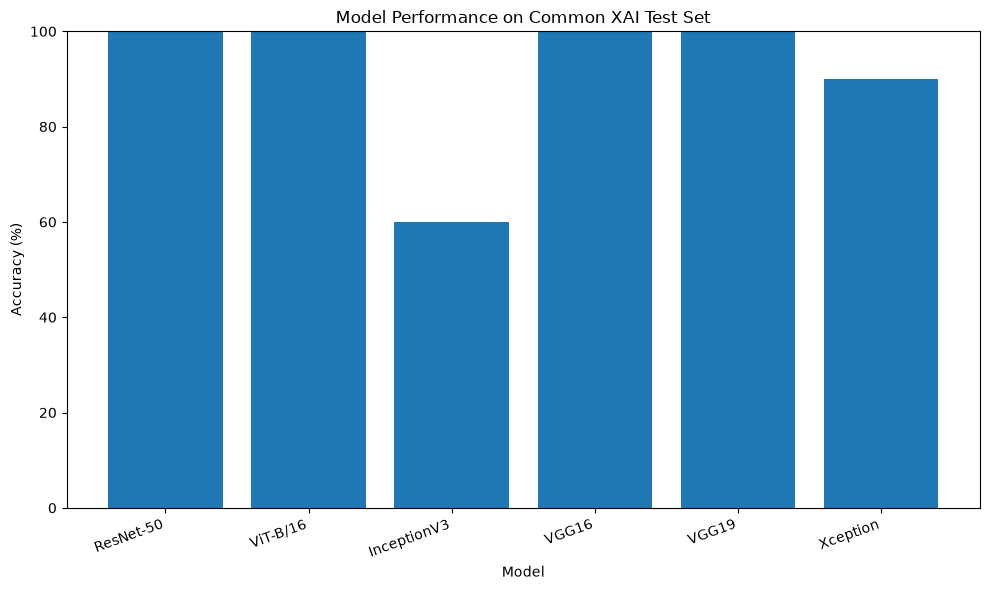

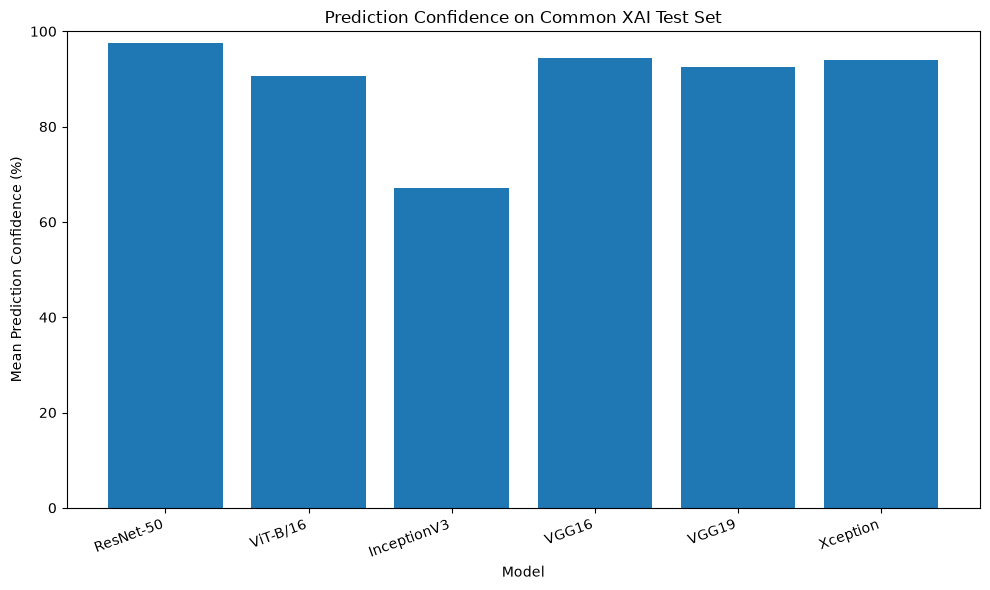


Figures saved:
D:\gpt\OcuVision-AI\results\cross_model_xai\figures\common_xai_model_accuracy.png
D:\gpt\OcuVision-AI\results\cross_model_xai\figures\common_xai_model_confidence.png


In [19]:
# ============================================================
# CELL 11 — XAI MODEL PERFORMANCE FIGURE
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

ROOT = r"D:\gpt\OcuVision-AI"

BASE_DIR = os.path.join(
    ROOT,
    "results",
    "cross_model_xai"
)

SUMMARY_CSV = os.path.join(
    BASE_DIR,
    "xai_model_summary.csv"
)

FIG_DIR = os.path.join(
    BASE_DIR,
    "figures"
)

os.makedirs(
    FIG_DIR,
    exist_ok=True
)

df = pd.read_csv(SUMMARY_CSV)

# ------------------------------------------------------------
# Accuracy figure
# ------------------------------------------------------------
plt.figure(figsize=(10, 6))

plt.bar(
    df["model"],
    df["accuracy_on_common_xai_set"] * 100
)

plt.ylabel("Accuracy (%)")
plt.xlabel("Model")
plt.title(
    "Model Performance on Common XAI Test Set"
)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.ylim(0, 100)

plt.tight_layout()

accuracy_path = os.path.join(
    FIG_DIR,
    "common_xai_model_accuracy.png"
)

plt.savefig(
    accuracy_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Confidence figure
# ------------------------------------------------------------
plt.figure(figsize=(10, 6))

plt.bar(
    df["model"],
    df["mean_confidence"] * 100
)

plt.ylabel("Mean Prediction Confidence (%)")
plt.xlabel("Model")
plt.title(
    "Prediction Confidence on Common XAI Test Set"
)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.ylim(0, 100)

plt.tight_layout()

confidence_path = os.path.join(
    FIG_DIR,
    "common_xai_model_confidence.png"
)

plt.savefig(
    confidence_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFigures saved:")
print(accuracy_path)
print(confidence_path)

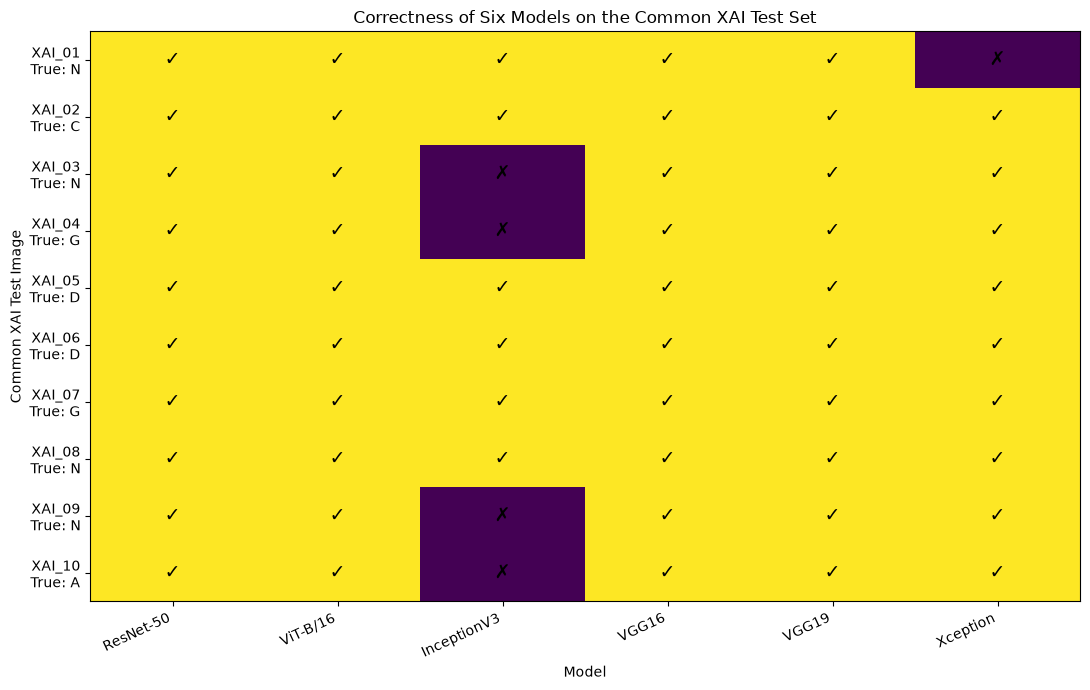


COMMON XAI SET CORRECTNESS
ResNet-50      : 10/10 (100.0%)
ViT-B/16       : 10/10 (100.0%)
InceptionV3    : 6/10 (60.0%)
VGG16          : 10/10 (100.0%)
VGG19          : 10/10 (100.0%)
Xception       : 9/10 (90.0%)

Saved:
D:\gpt\OcuVision-AI\results\cross_model_xai\figures\xai_model_correctness_heatmap.png


In [20]:
# ============================================================
# CELL 12 — XAI MODEL AGREEMENT / CORRECTNESS HEATMAP
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
ROOT = r"D:\gpt\OcuVision-AI"

BASE_DIR = os.path.join(
    ROOT,
    "results",
    "cross_model_xai"
)

PRED_CSV = os.path.join(
    BASE_DIR,
    "six_model_xai_predictions.csv"
)

FIG_DIR = os.path.join(
    BASE_DIR,
    "figures"
)

os.makedirs(FIG_DIR, exist_ok=True)

# ------------------------------------------------------------
# Load predictions
# ------------------------------------------------------------
df = pd.read_csv(PRED_CSV)

models = {
    "ResNet-50": "resnet50",
    "ViT-B/16": "vit_b16",
    "InceptionV3": "inception_v3",
    "VGG16": "vgg16",
    "VGG19": "vgg19",
    "Xception": "xception"
}

# ------------------------------------------------------------
# Build correctness matrix
# 1 = correct
# 0 = incorrect
# ------------------------------------------------------------
correctness = []

for _, row in df.iterrows():

    row_values = []

    for model_name, prefix in models.items():

        prediction = row[f"{prefix}_prediction"]
        true_class = row["true_class"]

        row_values.append(
            int(prediction == true_class)
        )

    correctness.append(row_values)

correctness_matrix = np.array(correctness)

# ------------------------------------------------------------
# Create labels
# ------------------------------------------------------------
image_labels = [
    f"{row['sample_id']}\nTrue: {row['true_class']}"
    for _, row in df.iterrows()
]

model_labels = list(models.keys())

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(11, 7)
)

im = ax.imshow(
    correctness_matrix,
    aspect="auto"
)

ax.set_xticks(
    np.arange(len(model_labels))
)

ax.set_xticklabels(
    model_labels,
    rotation=25,
    ha="right"
)

ax.set_yticks(
    np.arange(len(image_labels))
)

ax.set_yticklabels(
    image_labels
)

ax.set_xlabel("Model")
ax.set_ylabel("Common XAI Test Image")

ax.set_title(
    "Correctness of Six Models on the Common XAI Test Set"
)

# ------------------------------------------------------------
# Add values inside cells
# ------------------------------------------------------------
for i in range(
    correctness_matrix.shape[0]
):
    for j in range(
        correctness_matrix.shape[1]
    ):

        ax.text(
            j,
            i,
            "✓" if correctness_matrix[i, j] == 1 else "✗",
            ha="center",
            va="center",
            fontsize=14
        )

plt.tight_layout()

output_path = os.path.join(
    FIG_DIR,
    "xai_model_correctness_heatmap.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Print per-model results
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("COMMON XAI SET CORRECTNESS")
print("=" * 70)

for j, model_name in enumerate(model_labels):

    correct_count = correctness_matrix[:, j].sum()

    print(
        f"{model_name:15s}: "
        f"{correct_count}/10 "
        f"({correct_count / 10:.1%})"
    )

print("\nSaved:")
print(output_path)

In [21]:
# ============================================================
# CELL 13 — FINAL XAI CASE ANALYSIS
# ============================================================

import os
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
ROOT = r"D:\gpt\OcuVision-AI"

BASE_DIR = os.path.join(
    ROOT,
    "results",
    "cross_model_xai"
)

PRED_CSV = os.path.join(
    BASE_DIR,
    "six_model_xai_predictions.csv"
)

OUT_CSV = os.path.join(
    BASE_DIR,
    "final_xai_case_analysis.csv"
)

# ------------------------------------------------------------
# Load
# ------------------------------------------------------------
df = pd.read_csv(PRED_CSV)

models = {
    "ResNet-50": "resnet50",
    "ViT-B/16": "vit_b16",
    "InceptionV3": "inception_v3",
    "VGG16": "vgg16",
    "VGG19": "vgg19",
    "Xception": "xception"
}

# ------------------------------------------------------------
# Analyze every image
# ------------------------------------------------------------
results = []

for _, row in df.iterrows():

    true_class = row["true_class"]

    predictions = {}
    confidences = {}

    for model_name, prefix in models.items():

        predictions[model_name] = row[
            f"{prefix}_prediction"
        ]

        confidences[model_name] = row[
            f"{prefix}_confidence"
        ]

    correct_models = [
        model
        for model in models
        if predictions[model] == true_class
    ]

    incorrect_models = [
        model
        for model in models
        if predictions[model] != true_class
    ]

    unique_predictions = set(
        predictions.values()
    )

    # Majority prediction
    counts = pd.Series(
        list(predictions.values())
    ).value_counts()

    majority_prediction = counts.index[0]
    majority_count = counts.iloc[0]

    # Average confidence
    mean_confidence = np.mean(
        list(confidences.values())
    )

    # Confidence of wrong models
    wrong_confidences = [
        confidences[m]
        for m in incorrect_models
    ]

    mean_wrong_confidence = (
        np.mean(wrong_confidences)
        if wrong_confidences
        else np.nan
    )

    results.append({
        "sample_id": row["sample_id"],
        "filename": row["filename"],
        "true_class": true_class,

        "majority_prediction":
            majority_prediction,

        "majority_count":
            majority_count,

        "correct_model_count":
            len(correct_models),

        "incorrect_model_count":
            len(incorrect_models),

        "correct_models":
            ", ".join(correct_models)
            if correct_models
            else "None",

        "incorrect_models":
            ", ".join(incorrect_models)
            if incorrect_models
            else "None",

        "distinct_predictions":
            len(unique_predictions),

        "all_models_correct":
            len(correct_models) == 6,

        "all_models_agree":
            len(unique_predictions) == 1,

        "mean_confidence":
            mean_confidence,

        "mean_wrong_prediction_confidence":
            mean_wrong_confidence
    })

# ------------------------------------------------------------
# DataFrame
# ------------------------------------------------------------
analysis_df = pd.DataFrame(results)

# ------------------------------------------------------------
# Difficulty score
# Lower = harder
# ------------------------------------------------------------
analysis_df["difficulty_score"] = (
    analysis_df["correct_model_count"]
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------
analysis_df.to_csv(
    OUT_CSV,
    index=False
)

# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("FINAL XAI CASE ANALYSIS")
print("=" * 75)

print(
    analysis_df[
        [
            "sample_id",
            "true_class",
            "majority_prediction",
            "correct_model_count",
            "incorrect_model_count",
            "distinct_predictions",
            "all_models_correct",
            "all_models_agree"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# Hardest cases
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("HARDEST CASES")
print("=" * 75)

hardest = analysis_df.sort_values(
    [
        "correct_model_count",
        "distinct_predictions"
    ],
    ascending=[
        True,
        False
    ]
)

print(
    hardest[
        [
            "sample_id",
            "filename",
            "true_class",
            "majority_prediction",
            "correct_model_count",
            "incorrect_models",
            "mean_wrong_prediction_confidence"
        ]
    ].head(5).to_string(index=False)
)

# ------------------------------------------------------------
# Unanimous correct cases
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("UNANIMOUSLY CORRECT CASES")
print("=" * 75)

unanimous = analysis_df[
    analysis_df["all_models_correct"]
]

if len(unanimous) > 0:
    print(
        unanimous[
            [
                "sample_id",
                "filename",
                "true_class"
            ]
        ].to_string(index=False)
    )
else:
    print("No unanimous correct cases.")

# ------------------------------------------------------------
# Disagreement cases
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("DISAGREEMENT CASES")
print("=" * 75)

disagreements = analysis_df[
    ~analysis_df["all_models_agree"]
]

if len(disagreements) > 0:

    print(
        disagreements[
            [
                "sample_id",
                "filename",
                "true_class",
                "majority_prediction",
                "correct_model_count",
                "correct_models",
                "incorrect_models"
            ]
        ].to_string(index=False)
    )

else:
    print("No disagreement cases.")

# ------------------------------------------------------------
# Error responsibility by model
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("ERRORS BY MODEL")
print("=" * 75)

for model_name in models:

    errors = 0

    for _, row in df.iterrows():

        if row[
            f"{models[model_name]}_prediction"
        ] != row["true_class"]:

            errors += 1

    print(
        f"{model_name:15s}: "
        f"{errors}/10 incorrect"
    )

print("\nSaved:")
print(OUT_CSV)


FINAL XAI CASE ANALYSIS
sample_id true_class majority_prediction  correct_model_count  incorrect_model_count  distinct_predictions  all_models_correct  all_models_agree
   XAI_01          N                   N                    5                      1                     2               False             False
   XAI_02          C                   C                    6                      0                     1                True              True
   XAI_03          N                   N                    5                      1                     2               False             False
   XAI_04          G                   G                    5                      1                     2               False             False
   XAI_05          D                   D                    6                      0                     1                True              True
   XAI_06          D                   D                    6                      0                     

In [23]:
# ============================================================
# CELL 14 — FINAL RESEARCH SUMMARY (CORRECTED)
# ============================================================

import os
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
ROOT = r"D:\gpt\OcuVision-AI"

RESULTS_DIR = os.path.join(ROOT, "results")
XAI_DIR = os.path.join(
    RESULTS_DIR,
    "cross_model_xai"
)

OUT_DIR = os.path.join(
    RESULTS_DIR,
    "final_research_summary"
)

os.makedirs(OUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# Load ORIGINAL XAI predictions
# ------------------------------------------------------------
PRED_CSV = os.path.join(
    XAI_DIR,
    "six_model_xai_predictions.csv"
)

pred_df = pd.read_csv(PRED_CSV)

print("Prediction columns found:")
print(pred_df.columns.tolist())

# ------------------------------------------------------------
# Load FINAL XAI CASE ANALYSIS
# ------------------------------------------------------------
CASE_CSV = os.path.join(
    XAI_DIR,
    "final_xai_case_analysis.csv"
)

case_df = pd.read_csv(CASE_CSV)

# ------------------------------------------------------------
# Official frozen results
# ------------------------------------------------------------
official_results = pd.DataFrame([
    {
        "model": "ResNet-50",
        "test_accuracy": 81.24,
        "macro_precision": 81.07,
        "macro_recall": 85.51,
        "macro_f1": 82.58,
        "weighted_f1": 81.30
    },
    {
        "model": "ViT-B/16",
        "test_accuracy": 77.70,
        "macro_precision": 83.08,
        "macro_recall": 79.58,
        "macro_f1": 80.61,
        "weighted_f1": 77.84
    },
    {
        "model": "InceptionV3",
        "test_accuracy": np.nan,
        "macro_precision": np.nan,
        "macro_recall": np.nan,
        "macro_f1": np.nan,
        "weighted_f1": np.nan
    },
    {
        "model": "VGG16",
        "test_accuracy": np.nan,
        "macro_precision": np.nan,
        "macro_recall": np.nan,
        "macro_f1": np.nan,
        "weighted_f1": np.nan
    },
    {
        "model": "VGG19",
        "test_accuracy": np.nan,
        "macro_precision": np.nan,
        "macro_recall": np.nan,
        "macro_f1": np.nan,
        "weighted_f1": np.nan
    },
    {
        "model": "Xception",
        "test_accuracy": np.nan,
        "macro_precision": np.nan,
        "macro_recall": np.nan,
        "macro_f1": np.nan,
        "weighted_f1": np.nan
    }
])

# ------------------------------------------------------------
# Model configuration
# ------------------------------------------------------------
models = {
    "ResNet-50": "resnet50",
    "ViT-B/16": "vit_b16",
    "InceptionV3": "inception_v3",
    "VGG16": "vgg16",
    "VGG19": "vgg19",
    "Xception": "xception"
}

# ------------------------------------------------------------
# Calculate XAI-set performance
# from ORIGINAL prediction CSV
# ------------------------------------------------------------
xai_model_rows = []

for model_name, prefix in models.items():

    prediction_col = f"{prefix}_prediction"
    confidence_col = f"{prefix}_confidence"

    # Safety check
    if prediction_col not in pred_df.columns:
        print(
            f"WARNING: Missing {prediction_col}"
        )
        continue

    correct = (
        pred_df[prediction_col]
        == pred_df["true_class"]
    )

    xai_model_rows.append({
        "model": model_name,
        "xai_correct": int(correct.sum()),
        "xai_total": len(pred_df),
        "xai_accuracy": correct.mean() * 100,
        "xai_mean_confidence":
            pred_df[confidence_col].mean() * 100
    })

xai_model_df = pd.DataFrame(
    xai_model_rows
)

# ------------------------------------------------------------
# Merge official + XAI results
# ------------------------------------------------------------
final_model_summary = official_results.merge(
    xai_model_df,
    on="model",
    how="left"
)

# ------------------------------------------------------------
# Overall XAI statistics
# ------------------------------------------------------------
xai_stats = {
    "common_xai_images": len(case_df),

    "unanimously_correct_images":
        int(
            case_df[
                "all_models_correct"
            ].sum()
        ),

    "unanimous_agreement_images":
        int(
            case_df[
                "all_models_agree"
            ].sum()
        ),

    "disagreement_images":
        int(
            (~case_df[
                "all_models_agree"
            ]).sum()
        ),

    "mean_correct_models_per_image":
        case_df[
            "correct_model_count"
        ].mean(),

    "mean_correct_models_percent":
        case_df[
            "correct_model_count"
        ].mean() / 6 * 100
}

# ------------------------------------------------------------
# Save files
# ------------------------------------------------------------
official_path = os.path.join(
    OUT_DIR,
    "official_model_results.csv"
)

xai_path = os.path.join(
    OUT_DIR,
    "xai_model_results.csv"
)

final_path = os.path.join(
    OUT_DIR,
    "final_model_research_summary.csv"
)

stats_path = os.path.join(
    OUT_DIR,
    "xai_overall_statistics.csv"
)

official_results.to_csv(
    official_path,
    index=False
)

xai_model_df.to_csv(
    xai_path,
    index=False
)

final_model_summary.to_csv(
    final_path,
    index=False
)

pd.DataFrame(
    [xai_stats]
).to_csv(
    stats_path,
    index=False
)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------
print("\n" + "=" * 80)
print("FINAL MODEL RESEARCH SUMMARY")
print("=" * 80)

print(
    final_model_summary.to_string(
        index=False
    )
)

print("\n" + "=" * 80)
print("XAI OVERALL STATISTICS")
print("=" * 80)

for key, value in xai_stats.items():

    if isinstance(value, float):
        print(
            f"{key}: {value:.2f}"
        )
    else:
        print(
            f"{key}: {value}"
        )

print("\n" + "=" * 80)
print("FILES CREATED")
print("=" * 80)

print(final_path)
print(xai_path)
print(stats_path)

Prediction columns found:
['sample_id', 'filename', 'image_path', 'true_class', 'resnet50_prediction', 'resnet50_confidence', 'vit_b16_prediction', 'vit_b16_confidence', 'inception_v3_prediction', 'inception_v3_confidence', 'vgg16_prediction', 'vgg16_confidence', 'vgg19_prediction', 'vgg19_confidence', 'xception_prediction', 'xception_confidence']

FINAL MODEL RESEARCH SUMMARY
      model  test_accuracy  macro_precision  macro_recall  macro_f1  weighted_f1  xai_correct  xai_total  xai_accuracy  xai_mean_confidence
  ResNet-50          81.24            81.07         85.51     82.58        81.30           10         10         100.0            97.518644
   ViT-B/16          77.70            83.08         79.58     80.61        77.84           10         10         100.0            90.637879
InceptionV3            NaN              NaN           NaN       NaN          NaN            6         10          60.0            67.118762
      VGG16            NaN              NaN           NaN   

In [26]:
# ============================================================
# CELL 17 — FIND INCEPTIONV3 + XCEPTION TEST METRICS
# ============================================================

import os
import re

ROOT = r"D:\gpt\OcuVision-AI"

targets = [
    "inception_v3",
    "inceptionv3",
    "xception"
]

metric_words = [
    "test accuracy",
    "test_accuracy",
    "accuracy",
    "macro precision",
    "macro_precision",
    "macro recall",
    "macro_recall",
    "macro f1",
    "macro_f1",
    "weighted f1",
    "weighted_f1",
    "classification report"
]

extensions = {
    ".py",
    ".ipynb",
    ".csv",
    ".json",
    ".txt",
    ".log"
}

# ------------------------------------------------------------
# Search
# ------------------------------------------------------------
matches = []

for root, dirs, files in os.walk(ROOT):

    # Skip virtual environment and cache folders
    dirs[:] = [
        d for d in dirs
        if d not in {
            ".venv",
            "__pycache__",
            ".git"
        }
    ]

    for filename in files:

        ext = os.path.splitext(filename)[1].lower()

        if ext not in extensions:
            continue

        path = os.path.join(root, filename)

        try:
            with open(
                path,
                "r",
                encoding="utf-8",
                errors="ignore"
            ) as f:
                content = f.read()

        except Exception:
            continue

        lower = content.lower()

        has_model = any(
            target in lower
            for target in targets
        )

        has_metric = any(
            word in lower
            for word in metric_words
        )

        if not (has_model and has_metric):
            continue

        # ----------------------------------------------------
        # Extract useful lines
        # ----------------------------------------------------
        lines = content.splitlines()

        relevant_lines = []

        for i, line in enumerate(lines):

            line_lower = line.lower()

            if (
                any(
                    target in line_lower
                    for target in targets
                )
                or
                any(
                    word in line_lower
                    for word in metric_words
                )
            ):

                relevant_lines.append(
                    (
                        i + 1,
                        line.strip()
                    )
                )

        matches.append(
            (
                path,
                relevant_lines
            )
        )

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------
print("=" * 90)
print("INCEPTIONV3 / XCEPTION METRIC SEARCH")
print("=" * 90)

print(
    f"\nMatching files found: {len(matches)}"
)

for path, lines in matches:

    print("\n" + "-" * 90)
    print(path)
    print("-" * 90)

    # Show up to 40 relevant lines per file
    for line_number, line in lines[:40]:

        print(
            f"{line_number:5d}: {line}"
        )

print("\n" + "=" * 90)
print("SEARCH COMPLETE")
print("=" * 90)

INCEPTIONV3 / XCEPTION METRIC SEARCH

Matching files found: 10

------------------------------------------------------------------------------------------
D:\gpt\OcuVision-AI\notebooks\resnet50_local.ipynb
------------------------------------------------------------------------------------------
   46: "from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, precision_score, recall_score\n",
  129: "            except Exception as e:\n",
  648: "Val Loss:   0.5706 | Val Acc:   0.7789 | Val Macro F1: 0.7740\n",
  649: "⭐ New best validation Macro F1: 0.7740. Saving checkpoint...\n",
  687: "Val Loss:   0.4737 | Val Acc:   0.8000 | Val Macro F1: 0.8287\n",
  688: "⭐ New best validation Macro F1: 0.8287. Saving checkpoint...\n",
  726: "Val Loss:   0.4412 | Val Acc:   0.8239 | Val Macro F1: 0.8491\n",
  727: "⭐ New best validation Macro F1: 0.8491. Saving checkpoint...\n",
  765: "Val Loss:   0.4564 | Val Acc:   0.8172 | Val Macro F1: 0.8420\n",
  80

In [28]:
# ============================================================
# CELL 18 — OFFICIAL TEST EVALUATION
# INCEPTIONV3 + XCEPTION
# NO RETRAINING
# ============================================================

import os
import gc
import json
import torch
import torch.nn as nn
import pandas as pd
import numpy as np

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

ROOT = r"D:\gpt\OcuVision-AI"

DATA_DIR = os.path.join(
    ROOT,
    "data",
    "preprocessed"
)

MODEL_DIR = os.path.join(
    ROOT,
    "models"
)

OUT_DIR = os.path.join(
    ROOT,
    "results",
    "final_research_summary"
)

os.makedirs(OUT_DIR, exist_ok=True)

classes = ["N", "D", "G", "C", "A", "H", "M"]
class_to_idx = {c: i for i, c in enumerate(classes)}

print("=" * 90)
print("OFFICIAL TEST EVALUATION")
print("=" * 90)

# ------------------------------------------------------------
# 1. Recreate EXACT official test split
# ------------------------------------------------------------

from sklearn.model_selection import train_test_split

records = []

for cls in classes:

    folder = os.path.join(DATA_DIR, cls)

    if not os.path.isdir(folder):
        raise FileNotFoundError(
            f"Class folder not found: {folder}"
        )

    for filename in os.listdir(folder):

        path = os.path.join(
            folder,
            filename
        )

        if os.path.isfile(path):

            records.append({
                "filename": filename,
                "label": cls,
                "path": path
            })

df = pd.DataFrame(records)

print("\nTotal images:", len(df))

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

test_df = test_df.reset_index(drop=True)

print("Test images:", len(test_df))

if len(test_df) != 1045:
    raise RuntimeError(
        f"Expected 1045 test images, got {len(test_df)}"
    )

# ------------------------------------------------------------
# 2. Dataset
# ------------------------------------------------------------

eval_transform_299 = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class TestDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = Image.open(
            row["path"]
        ).convert("RGB")

        image = self.transform(image)

        label = class_to_idx[
            row["label"]
        ]

        return image, label


test_dataset = TestDataset(
    test_df,
    eval_transform_299
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

device = torch.device("cpu")

print("Evaluation device:", device)

# ------------------------------------------------------------
# 3. Evaluation function
# ------------------------------------------------------------

def evaluate_model(model, loader):

    model.eval()

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            outputs = model(images)

            # InceptionV3 can return InceptionOutputs
            if hasattr(outputs, "logits"):
                outputs = outputs.logits

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            all_labels.extend(
                labels.numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_precision = precision_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    macro_recall = recall_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        all_labels,
        all_predictions,
        average="weighted",
        zero_division=0
    )

    return {
        "test_accuracy": accuracy * 100,
        "macro_precision": macro_precision * 100,
        "macro_recall": macro_recall * 100,
        "macro_f1": macro_f1 * 100,
        "weighted_f1": weighted_f1 * 100
    }


# ============================================================
# 4. INCEPTIONV3
# ============================================================

print("\n" + "=" * 90)
print("INCEPTIONV3")
print("=" * 90)

inception_checkpoint_path = os.path.join(
    MODEL_DIR,
    "inception_v3_best_checkpoint.pth"
)

if not os.path.exists(inception_checkpoint_path):
    raise FileNotFoundError(
        inception_checkpoint_path
    )

checkpoint = torch.load(
    inception_checkpoint_path,
    map_location="cpu",
    weights_only=False
)

inception = models.inception_v3(
    weights=None,
    aux_logits=True
)

inception.fc = nn.Linear(
    inception.fc.in_features,
    len(classes)
)

inception.AuxLogits.fc = nn.Linear(
    inception.AuxLogits.fc.in_features,
    len(classes)
)

inception.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

inception = inception.to(device)

inception_results = evaluate_model(
    inception,
    test_loader
)

print("\nInceptionV3 official test results:")

for key, value in inception_results.items():
    print(
        f"{key}: {value:.4f}%"
    )

del inception
del checkpoint

gc.collect()

# ============================================================
# 5. XCEPTION
# ============================================================

print("\n" + "=" * 90)
print("XCEPTION")
print("=" * 90)

import timm

xception_checkpoint_path = os.path.join(
    MODEL_DIR,
    "xception_best_checkpoint.pth"
)

if not os.path.exists(xception_checkpoint_path):
    raise FileNotFoundError(
        xception_checkpoint_path
    )

checkpoint = torch.load(
    xception_checkpoint_path,
    map_location="cpu",
    weights_only=False
)

xception = timm.create_model(
    "legacy_xception",
    pretrained=False,
    num_classes=len(classes)
)

xception.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

xception = xception.to(device)

xception_results = evaluate_model(
    xception,
    test_loader
)

print("\nXception official test results:")

for key, value in xception_results.items():
    print(
        f"{key}: {value:.4f}%"
    )

# ------------------------------------------------------------
# 6. Save results
# ------------------------------------------------------------

official_rows = [
    {
        "model": "InceptionV3",
        **inception_results
    },
    {
        "model": "Xception",
        **xception_results
    }
]

new_metrics = pd.DataFrame(
    official_rows
)

output_file = os.path.join(
    OUT_DIR,
    "inception_xception_official_test_metrics.csv"
)

new_metrics.to_csv(
    output_file,
    index=False
)

print("\n" + "=" * 90)
print("NEW OFFICIAL TEST METRICS")
print("=" * 90)

print(
    new_metrics.to_string(
        index=False
    )
)

print("\nSaved:")
print(output_file)

OFFICIAL TEST EVALUATION

Total images: 10449
Test images: 1045
Evaluation device: cpu

INCEPTIONV3


d:\gpt\OcuVision-AI\.venv\Lib\site-packages\torchvision\models\inception.py:43: FutureWarning: The default weight initialization of inception_v3 will be changed in future releases of torchvision. If you wish to keep the old behavior (which leads to long initialization times due to scipy/scipy#11299), please set init_weights=True.
  warnings.warn(



InceptionV3 official test results:
test_accuracy: 54.9282%
macro_precision: 57.7116%
macro_recall: 54.6987%
macro_f1: 50.9329%
weighted_f1: 52.9690%

XCEPTION

Xception official test results:
test_accuracy: 96.3636%
macro_precision: 96.0574%
macro_recall: 96.0788%
macro_f1: 96.0353%
weighted_f1: 96.3493%

NEW OFFICIAL TEST METRICS
      model  test_accuracy  macro_precision  macro_recall  macro_f1  weighted_f1
InceptionV3      54.928230        57.711649     54.698703 50.932866    52.969043
   Xception      96.363636        96.057384     96.078788 96.035301    96.349285

Saved:
D:\gpt\OcuVision-AI\results\final_research_summary\inception_xception_official_test_metrics.csv
